# Do temperature and seeds change an LLM's algorithm?

**Demo of `method.py`**, the orchestrator of a screen on **Qwen3-8B** that asks whether sampling temperature and
context seeds give a model *new ideas* or only *new wording*. The model gets two path-search coding tasks:

- **T1:** unweighted 4-connected grid path search. Any valid path is accepted, so BFS is not forced.
- **T2:** weighted single-pair shortest path on a directed graph.

The run made 5,220 generations with vLLM 0.11.0 on one RTX 5090. Each program was labelled by execution: hidden
tests decide correctness, a runtime-signature tracer and AST rules decide the algorithm, and a blind LLM judge settles
disagreements between the two. Every cue is compared with a no-cue baseline (arm A0) at matched decoding:

| Arm | Cue |
|---|---|
| A1 / A6 | temperature T ∈ {0.3, 0.7, 1.0, 1.3} × sampler {top-k=10, top-p=0.95}, thinking off / on |
| A2 | context seeds: entropy `seed=d32qxk4nt43`, word `seed=(horse chair roof love)`, semantic (a story that implies an approach without naming it) |
| A3 | instructions: "Be creative", "Make a new algorithm", "Make a fully novel algorithm never seen before", "First list 10 different approaches ... then implement one" |
| A4 | gen-then-select: the model lists 10 approaches, an external RNG picks one, the model implements it |
| A5 | forced implementations of each catalogue algorithm (they define the "mode subspace" in hidden-state space) |

**What this notebook runs** (CPU only; a few seconds of compute after the package installs):

1. `method.py` itself, split into cells. Its `output` stage (`build_method_out`) runs on **96 real T1 programs**
   loaded from `mini_demo_data.json`.
2. The AST half of the `label` stage (`labeller/ast_rules.py`), re-applied to every demo program.
3. The CPU-only sections of the `analyze` stage, copied from `analysis/`:
   - 8a: BFS share per decoding cell.
   - Per-condition summaries.
   - 8b: ideas × phrasings, with AST shingles, Jaccard clusters, DA@K and the PPI slope in T.
4. Plots that put the subset next to the recorded full-run results for both tasks, including the hidden-state
   geometry from the GPU `hooks` stage: an MDS of read-position centroids and the displacement ratios.

**What it does not run:** vLLM generation, the hidden-test harness and runtime tracer (both execute untrusted
model code), the Hugging Face activation hooks and the OpenRouter judge. Their code is shown where `method.py` calls
them, and their outputs come from the data file.

**Headline (full run):**

- Temperature and sampler do not change the algorithm. BFS on T1 is 797/800 with thinking off and 800/800 with
  thinking on; Dijkstra on T2 is 797/800 and 800/800.
- Phrasings multiply with T, while ideas stay at about 1.
- Random seeds move behaviour by ≤ 1 pp.
- Ideas diversify only under the semantic seed (T2: +66 pp toward Bellman-Ford), the "fully novel" and "list 10"
  instructions (T2: −15 / −11 pp Dijkstra) and gen-then-select, each at a cost in pass rate.
- The labeller gate failed by its strict criteria, so all results are descriptive.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (method.py logs through common.setup_logging)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib, scikit-learn — pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0', 'scikit-learn==1.6.1')

In [2]:
from __future__ import annotations

# --- original import block of method.py ---
import argparse
import hashlib
import json
import subprocess
import sys
import time
from pathlib import Path

# from common import (CATALOGUE, LOGS, RAW, RESULTS, TASK_TEXT, TESTS_DIR, read_jsonl, setup_logging,  # noqa: E402
#                     sha256_file, write_json)
# -> common.py is not shipped with the notebook; these names are defined in the "common.py helpers" cell below.

# --- imports of the inlined common.py / labeller/ast_rules.py / analysis/*.py code ---
import ast
import builtins
import math
import re
from collections import Counter, defaultdict
from typing import Any, Iterator, Sequence

import numpy as np

# --- notebook additions: tables and plots ---
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-1/experiment-6/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# guard against a stale file at the URL (a different schema): fall back to the local copy
if "samples" not in data:
    print("The file at GITHUB_DATA_URL has a different schema; using the local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
print(data["_about"]["source"])
print(data["_about"]["selection"])
print({k: len(v) for k, v in data.items() if isinstance(v, (list, dict)) and k != "_about"})

The file at GITHUB_DATA_URL has a different schema; using the local mini_demo_data.json
experiment art_UoCVh2Qe5RZ0 (Qwen3-8B screen: do temperature and seeds change the algorithm?)
T1 only. Per cell a fixed-seed draw (random.Random(20261025)); every label with >= 5% share of the cell in the full run is represented once before the quota is filled at random, and each A5 forced cell keeps one program labelled with its forced mode. Cell shares in this subset are illustrative, NOT estimates; full-run numbers are under 'analysis'.
{'samples': 96, 'raw': 96, 'analysis': 13, 'labeller_gate': 6, 'capacity': 16, 'gen_stats': 11, 'states_meta': 1, 'openrouter_costs': 506, 'env': 4, 'hidden_tests_sha256': 2, 'module_sha256': 26, 'r_centroids': 2}


## Configuration

All tunable values live in this cell.

- **`STAGE` and the four command-line values** feed `main()` at the places where `method.py` hard-codes them. They
  matter only for the GPU and API stages, which the demo does not run. `output` is the stage that runs from the demo
  data.
- **The demo-scale knobs** control how many programs per cell are analysed and how many bootstrap draws the confidence
  intervals use. The values used in the artifact are in the comments.
- **`DA_K`** must not exceed the number of correct programs in a cell, or DA@K is undefined (`None`). The artifact had
  about 100 programs per cell and used K = 25.

In [5]:
# ---- method.py command line (used only by the GPU / API stages, which need the full artifact) ----
STAGE = "output"          # method.py <stage>: setup | smoke | generate | label | gate | hooks | analyze | output | all
DEADLINE = None           # method.py --deadline HH:MM (passed to the generation stage)
N_THINK = 10              # gen/arms.py --n-think: paraphrases per thinking-on cell
LABEL_WORKERS = 12        # labeller/label.py --workers
JUDGE_CAP_USD = 1.0       # labeller/label.py --judge-cap: OpenRouter spend cap for the blind judge

# ---- demo scale (artifact values in the comments; scaled 2 -> 4 -> 7 programs per cell, ~20-70 s per clean run) ----
MAX_PER_CELL = 7          # programs kept per decoding/condition cell; 7 = all demo data (artifact: all ~100 per cell)
N_BOOT_SHARE = 2000       # paraphrase-cluster bootstrap draws for the 8a shares (artifact: 2000)
N_BOOT_PHRASING = 1000    # program-bootstrap draws for the 8b slopes in T (artifact: 1000)
DA_K = 5                  # K of DA@K for ideas and phrasings (artifact: 25, needs >= 25 correct programs per cell)
DA_K_MODAL = 5            # K of DA@K over the phrasings of the modal idea (artifact: 20)
THETAS = (0.7, 0.8, 0.9)  # Jaccard thresholds for phrasing clusters (artifact: (0.7, 0.8, 0.9))
LINKAGES = ("single", "complete")   # cluster linkages (artifact: ("single", "complete"))

## `common.py` helpers

`method.py` imports its paths, task texts, algorithm catalogue and JSON/logging helpers from `common.py`. The subset
that `method.py` and the analysis code below use is copied here verbatim, with one change: `WS` (the artifact folder)
becomes a local `method_ws/` folder, because a notebook has no `__file__`.

The **catalogue** lists the algorithms the labeller can recognise: 6 for T1 and 5 for T2. Everything else is labelled
`other`, `unparseable` or `unresolved`.

In [6]:
# ---- common.py (subset; verbatim except WS) ----
WS = Path.cwd() / "method_ws"   # common.py: WS = Path(__file__).resolve().parent  (the artifact folder)
LOGS = WS / "logs"
RESULTS = WS / "results"
RAW = RESULTS / "raw"
LABELS = RESULTS / "labels"
STATES = WS / "states"
FIGURES = WS / "figures"
PROMPTS_DIR = WS / "prompts"
TESTS_DIR = WS / "tests"
REFS_DIR = WS / "references"
FORECAST_DIR = WS / "forecast"
for _d in (LOGS, RESULTS, RAW, LABELS, STATES, FIGURES, PROMPTS_DIR, TESTS_DIR, REFS_DIR, FORECAST_DIR):
    _d.mkdir(parents=True, exist_ok=True)

TASKS = ("T1", "T2")
TASK_TEXT = {
    "T1": ("Write a Python function solve(grid, start, goal). grid is a list of strings of equal length; . is an "
           "open cell and # is a wall. start and goal are (row, col) tuples of open cells. Moves go up, down, left "
           "or right. Return any valid path from start to goal as a list of (row, col) tuples that begins with "
           "start, ends with goal and visits only open cells, or [] if goal is unreachable. Grids have at most 30 "
           "rows and 30 columns. Return only one ```python code block containing solve and any helpers."),
    "T2": ("Write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100); "
           "edges is a list of (u, v, w) tuples with integer weight 0 <= w <= 100; cycles, self-loops and parallel "
           "edges may occur. Return the length of the shortest path from s to t, 0 if s == t, or -1 if t is "
           "unreachable. Return only one ```python code block containing solve and any helpers."),
}

# Catalogue: mode -> (display name used in forced prompts, one-line definition used by the judge)
CATALOGUE: dict[str, dict[str, tuple[str, str]]] = {
    "T1": {
        "bfs": ("breadth-first search (BFS)",
                "breadth-first search: a FIFO queue expands cells in order of distance from start"),
        "dfs": ("depth-first search (DFS)",
                "depth-first search: a LIFO stack or recursion follows one branch as deep as possible before "
                "backtracking (recursive and iterative versions are the same algorithm)"),
        "bidirectional_bfs": ("bidirectional breadth-first search",
                              "bidirectional BFS: two FIFO frontiers grow from start and from goal and stop "
                              "when they meet"),
        "iddfs": ("iterative deepening depth-first search (IDDFS)",
                  "iterative deepening DFS: repeated depth-limited DFS with an increasing depth limit"),
        "astar_greedy": ("A* search with a Manhattan-distance heuristic",
                         "heuristic best-first search: a priority queue ordered by a goal-distance heuristic "
                         "h (greedy best-first) or by g+h (A*)"),
        "dijkstra_unit": ("Dijkstra's algorithm with a priority queue",
                          "Dijkstra / uniform-cost search: a priority queue ordered by path cost g only, "
                          "no heuristic"),
    },
    "T2": {
        "dijkstra": ("Dijkstra's algorithm",
                     "Dijkstra: repeatedly settle the unsettled node with the smallest tentative distance "
                     "(binary heap or linear scan), relaxing its outgoing edges"),
        "bellman_ford_spfa": ("the Bellman-Ford algorithm",
                              "Bellman-Ford / SPFA: relax all edges in rounds until nothing changes, or a FIFO "
                              "queue of nodes whose distance changed (nodes may be processed many times)"),
        "bidirectional_dijkstra": ("bidirectional Dijkstra's algorithm",
                                   "bidirectional Dijkstra: one Dijkstra search forward from s and one backward "
                                   "from t over reversed edges, stopping when the frontiers meet"),
        "floyd_warshall": ("the Floyd-Warshall algorithm",
                           "Floyd-Warshall: all-pairs dynamic programming over an n x n distance matrix with "
                           "three nested loops over k, i, j"),
        "dial": ("Dial's algorithm (a bucket-based priority queue)",
                 "Dial's algorithm: Dijkstra with an array of buckets indexed by integer distance instead of "
                 "a heap"),
    },
}
MODES = {t: list(CATALOGUE[t]) for t in TASKS}
PRIMARY_MODE = {"T1": "bfs", "T2": "dijkstra"}
NON_CLASSIFIED = {"other", "unparseable", "unresolved", None}


def sha256_file(path: Path) -> str:
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def read_jsonl(path: Path) -> Iterator[dict]:
    path = Path(path)
    if not path.exists():
        return
    with path.open() as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                yield json.loads(line)
            except json.JSONDecodeError:
                continue  # a torn last line after a crash; the row is regenerated on resume


def write_json(path: Path, obj: Any, indent: int | None = 2) -> None:
    tmp = Path(str(path) + ".tmp")
    tmp.write_text(json.dumps(obj, indent=indent, default=_json_default))
    tmp.replace(path)


def _json_default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return None if not math.isfinite(float(o)) else float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serializable: {type(o)}")


def setup_logging(name: str, level: str = "INFO"):
    from loguru import logger
    logger.remove()
    logger.add(sys.stdout, level=level, format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")
    return logger


for t in TASKS:
    print(t, "catalogue:", ", ".join(MODES[t]), "| primary mode:", PRIMARY_MODE[t])

T1 catalogue: bfs, dfs, bidirectional_bfs, iddfs, astar_greedy, dijkstra_unit | primary mode: bfs
T2 catalogue: dijkstra, bellman_ford_spfa, bidirectional_dijkstra, floyd_warshall, dial | primary mode: dijkstra


## `method.py`: module-level constants

- **`MODULES`** lists every file whose sha256 goes into the output, so a reader can check that they run the same
  code.
- **`DEVIATIONS`** records every departure from the pre-registered plan: what changed, why, and the effect on the
  results.

Both are copied unchanged.

In [7]:
PY = sys.executable
logger = setup_logging("method")

MODULES = ["common.py", "tasks/t1_grid.py", "tasks/t2_sssp.py", "harness/run_tests.py", "harness/_driver.py",
           "labeller/_trace_driver.py", "labeller/tracer.py", "labeller/ast_rules.py", "labeller/judge.py",
           "labeller/label.py", "labeller/gold.py", "prompts/build.py", "gen/arms.py", "hooks/states.py",
           "analysis/metrics.py", "analysis/behaviour.py", "analysis/phrasing.py", "analysis/subspace.py",
           "analysis/thinking.py", "analysis/verdicts.py", "analysis/figures.py", "analysis/run_all.py",
           "analysis/test_metrics.py", "labeller/test_rewrite.py", "verify_headlines.py", "method.py"]

DEVIATIONS = [
    dict(what="GPU was an RTX 5090 (32 GB) instead of a 20 GB card: max_num_seqs=128 (plan 16) and thinking-on "
              "cells have N=100 (10 paraphrases x 10) instead of N=50; all four thinking-on cells per task ran",
         why="more KV-cache capacity (92k tokens) and ~4k tok/s throughput", effect="more power for thinking-on "
         "cells; no planned arm was dropped"),
    dict(what="vLLM 0.11.0 started with enforce_eager=True (no CUDA graphs / torch.compile)",
         why="the container has no C compiler, so Triton/Inductor compilation cannot run", effect="speed only"),
    dict(what="HF_HOME was not set to ./hf_cache; Qwen/Qwen3-8B was read from the run's shared HF cache",
         why="the run's shared cache variables must not be overridden", effect="none on outputs"),
    dict(what="per-request seed = stable hash of (task, condition, paraphrase, sample, arm, T, sampler, thinking) "
              "instead of (task, condition, paraphrase, sample)",
         why="so that different decoding cells are independent draws rather than common-random-number pairs",
         effect="cells are independent samples, matching the per-cell bootstrap"),
    dict(what="forced:X uses 20 frames = 10 neutral preambles x 2 templates; described:X uses 2 name-free "
              "descriptions x 5 preambles per mode", why="the plan fixes counts but not the frame construction",
         effect="none"),
    dict(what="A4 stage 1 has no paraphrase preambles (paraphrase_id=-1); its bootstrap treats each sample as a cluster",
         why="the plan's stage-1 prompt has no preamble", effect="none"),
    dict(what="tracer uses sys.settrace for both call/return (recursion depth, call expansions) and line events",
         why="one trace function covers both; sys.setprofile would duplicate the call bookkeeping", effect="none"),
    dict(what="IDDFS reference written in the common recursive form (best-depth map per iteration) plus an "
              "iterative-stack variant; serpentine T1 test fixed (its goal cell was a wall)",
         why="first version did not match model-written IDDFS and the test case violated the spec",
         effect="labeller validated on both IDDFS forms; hidden tests regenerated before any scoring"),
    dict(what="tracer crafted graphs W1/W2 made strongly connected (Hamiltonian cycle) with a FIFO re-relaxation "
              "gadget next to s; Floyd-Warshall rule also accepts growth >= 2.2 with >= n^3/2 line events",
         why="on the planned generator SPFA never re-popped a node and an INF-skipping Floyd-Warshall grew as n^1.4",
         effect="100% runtime labels on references (pre-gate change, logged)"),
    dict(what="two rounds of labeller signature revision after the first gate (see labeller_gate.revisions)",
         why="gate failures traced to stale-pop handling, Bellman-Ford over adjacency lists, and sequential double "
             "Dijkstra mislabelled bidirectional", effect="samples needing the judge fell from 247 to 116 (of 5,220)"),
    dict(what="labeller gate failed on both tasks by the strict criterion and both tasks carry the flag "
              "'labeller_gate_failed'; their results are descriptive",
         why="kappa(runtime, AST) on the gold set is low by construction (the gold set oversamples disagreements; "
             "population kappa is 0.88 / 0.85); T2 gold agreement 70% because the gold judges call broken "
             "attempts 'other' while the pipeline labels the attempted structure",
         effect="verdicts are reported mechanically but marked descriptive; agreement on correct gold programs is "
                "92% on both tasks"),
    dict(what="probe nulls: 200 shuffled-label permutations for transfer accuracy in layers 8-28 (50 elsewhere); "
              "leave-one-frame-out null uses 20 permutations",
         why="time budget", effect="l* selection uses the planned 200-permutation transfer null"),
    dict(what="S_nat skipped on both tasks; variance split uses S_gen (primary) and S_R",
         why="natural samples have < 2 modes with >= 5 samples (fallback 5)", effect="as planned"),
    dict(what="variance-split data-matched null frames are drawn inside the top-50 PCs of the pooled generated-"
              "position states of the task (not the R states)",
         why="the null should match the space whose variance is being split", effect="excess-share values"),
    dict(what="max_model_len=4096 (shared protocol 2048) and max_tokens=1536 for instr_enumerate",
         why="planned deviations", effect="none on thinking-off outputs"),
]

print(f"{len(MODULES)} modules are hashed into the output; {len(DEVIATIONS)} recorded deviations from the plan:")
for i, dv in enumerate(DEVIATIONS, 1):
    print(f"{i:2d}. {dv['what'][:110]}{' ...' if len(dv['what']) > 110 else ''}")

26 modules are hashed into the output; 15 recorded deviations from the plan:
 1. GPU was an RTX 5090 (32 GB) instead of a 20 GB card: max_num_seqs=128 (plan 16) and thinking-on cells have N=1 ...
 2. vLLM 0.11.0 started with enforce_eager=True (no CUDA graphs / torch.compile)
 3. HF_HOME was not set to ./hf_cache; Qwen/Qwen3-8B was read from the run's shared HF cache
 4. per-request seed = stable hash of (task, condition, paraphrase, sample, arm, T, sampler, thinking) instead of  ...
 5. forced:X uses 20 frames = 10 neutral preambles x 2 templates; described:X uses 2 name-free descriptions x 5 pr ...
 6. A4 stage 1 has no paraphrase preambles (paraphrase_id=-1); its bootstrap treats each sample as a cluster
 7. tracer uses sys.settrace for both call/return (recursion depth, call expansions) and line events
 8. IDDFS reference written in the common recursive form (best-depth map per iteration) plus an iterative-stack va ...
 9. tracer crafted graphs W1/W2 made strongly connected (Hamilt

## `method.py`: running a stage in its own process

`run()` launches one stage script in a subprocess and appends its output to `logs/<log>`. Each GPU stage gets its own
process, so vLLM and Hugging Face never share the GPU.

`stage_setup()` runs eight setup scripts:

- hidden tests: 41 T1 and 39 T2 cases from fixed RNG seeds, with per-case time limits;
- the reference gate: all 16 reference implementations must pass, and negative controls must fail;
- the prompt-scaffold assertions: no algorithm name appears in seeds or descriptions, and every condition shares the
  same final tokens;
- the labeller and metric self-tests.

It refuses to continue unless the hash-committed forecast exists.

Both functions need the artifact's module files (`tasks/`, `harness/`, `labeller/`, ...), so the demo defines them
but does not call them. They are copied unchanged.

In [8]:
def run(cmd: list[str], log: str) -> None:
    logger.info("$ " + " ".join(cmd).replace(str(WS) + "/", ""))
    t0 = time.time()
    with (LOGS / log).open("a") as f:
        r = subprocess.run(cmd, cwd=WS, stdout=f, stderr=subprocess.STDOUT)
    logger.info(f"exit {r.returncode} after {time.time() - t0:.0f}s (log: logs/{log})")
    if r.returncode != 0:
        raise RuntimeError(f"stage failed: {' '.join(cmd)}")


def stage_setup() -> None:
    run([PY, "tasks/t1_grid.py"], "setup.log")
    run([PY, "tasks/t2_sssp.py"], "setup.log")
    run([PY, "harness/run_tests.py"], "setup.log")
    run([PY, "prompts/build.py"], "setup.log")
    run([PY, "labeller/tracer.py"], "setup.log")
    run([PY, "labeller/ast_rules.py"], "setup.log")
    run([PY, "analysis/test_metrics.py"], "setup.log")
    run([PY, "labeller/test_rewrite.py"], "setup.log")
    fc = WS / "forecast" / "predictions_screen.json"
    if not fc.exists():
        raise RuntimeError("forecast/predictions_screen.json must be written (and hashed) before sampling")
    (LOGS / "forecast_sha256.txt").write_text(sha256_file(fc) + "\n")

## Programs used in this run

In the artifact every stage reads all 5,220 rows of `results/samples.jsonl`. The demo data holds 96 T1 rows in the
same schema, drawn per cell with a fixed seed:

| Arm | Programs |
|---|---|
| A0 baseline | 4 |
| A1 grid | 7 in each of 8 cells |
| A2 seeds | 3 / 3 / 4 |
| A3 instructions | 3 / 3 / 4 / 3 |
| A4 gen-then-select | 7 |
| A5 forced | 1 per forced mode |

Every label with at least a 5% share of its cell in the full run is represented once. Cell shares in the subset
therefore illustrate what each cue produces; they are **not** estimates. This cell keeps the first `MAX_PER_CELL`
programs of each cell.

In [9]:
_cells = defaultdict(list)
for s in data["samples"]:
    d = s["decoding"]
    _cells[(s["arm"], s["condition"], d["T"], d["sampler"], d["thinking"])].append(s)
SAMPLES = [s for rows in _cells.values() for s in rows[:MAX_PER_CELL]]
print(f"{len(SAMPLES)} of {len(data['samples'])} demo programs used, from {len(_cells)} cells "
      f"(MAX_PER_CELL={MAX_PER_CELL})")
display(pd.DataFrame([dict(arm=k[0], condition=k[1], T=k[2], sampler=k[3], thinking=k[4], in_data=len(v),
                           used=min(len(v), MAX_PER_CELL), labels_used=dict(Counter(r["label"] for r in v[:MAX_PER_CELL])))
                      for k, v in _cells.items()]))

96 of 96 demo programs used, from 23 cells (MAX_PER_CELL=7)


,arm,condition,T,sampler,thinking,in_data,used,labels_used
0,A0,baseline,1.0,pure,False,4,4,{'bfs': 4}
1,A1,baseline,0.3,topk10,False,7,7,{'bfs': 7}
2,A1,baseline,0.3,topp095,False,7,7,{'bfs': 7}
3,A1,baseline,0.7,topk10,False,7,7,"{'bfs': 6, 'dfs': 1}"
4,A1,baseline,0.7,topp095,False,7,7,{'bfs': 7}
5,A1,baseline,1.0,topk10,False,7,7,{'bfs': 7}
6,A1,baseline,1.0,topp095,False,7,7,{'bfs': 7}
7,A1,baseline,1.3,topk10,False,7,7,{'bfs': 7}
8,A1,baseline,1.3,topp095,False,7,7,{'bfs': 7}
9,A2,seed_entropy,1.0,pure,False,3,3,{'bfs': 3}


## `method.py`: the `output` stage, `build_method_out()`

This stage joins every labelled program (`results/samples.jsonl`) with its raw generation
(`results/raw/<arm>.jsonl`), matched by `key`. Each pair becomes one row of the `exp_gen_sol_out` schema:

- **`input`**: the user message.
- **`output`**: the model's answer.
- **`predict_*`**: the final, runtime-tracer, AST and judge labels.
- **`metadata_*`**: arm, condition, paraphrase, decoding (T, sampler, top-k, top-p, thinking, seed), test results and
  the code-extraction rule. Gen-then-select rows also carry the selected item.

Everything else goes under `metadata`: analysis results, labeller gate, deviations, verdicts, forecast check, OpenRouter
spend and module hashes.

**Changes for the notebook:**

- Every file read is replaced by the matching entry of `data`. The original line is kept as a comment.
- `torch`, `transformers` and `vllm` were imported only to record their versions and the GPU name, so the recorded
  values are used instead.

In [10]:
def build_method_out() -> dict:
    # notebook: each file read is replaced by the matching entry of `data` (the original line is in the comment)
    A = data["analysis"]                 # json.loads((RESULTS / "analysis.json").read_text())
    gate = data["labeller_gate"]         # json.loads((RESULTS / "labeller_gate.json").read_text())
    cap = data["capacity"]               # json.loads((LOGS / "capacity.json").read_text())
    stats = data["gen_stats"]            # json.loads((LOGS / "gen_stats.json").read_text())
    meta_states = data["states_meta"]    # json.loads((WS / "states" / "meta.json").read_text())
    # import torch / import transformers / import vllm -> only their versions and the GPU name were read
    env = data["env"]

    def total_cost() -> float:           # from labeller.judge import total_cost (sum over logs/openrouter_costs.jsonl)
        return round(sum(r.get("cost", 0.0) for r in data["openrouter_costs"]), 6)

    raw = {}
    for r in data["raw"]:                # for f in sorted(RAW.glob("A*.jsonl")): for r in read_jsonl(f):
        raw[r["key"]] = r
    datasets = {"T1": [], "T2": []}
    for s in SAMPLES:                    # for s in read_jsonl(RESULTS / "samples.jsonl"):
        r = raw.get(s["key"], {})
        d = s["decoding"]
        ex = {
            "input": r.get("user_message", ""),
            "output": r.get("answer_text") or r.get("text") or "",
            "predict_algorithm_label": str(s["label"]),
            "predict_runtime_label": str(s.get("runtime_label")),
            "predict_ast_label": str(s.get("ast_label")),
            "predict_judge_label": str(s.get("judge_label")),
            "metadata_key": s["key"], "metadata_arm": s["arm"], "metadata_condition": s["condition"],
            "metadata_paraphrase_id": s["paraphrase_id"], "metadata_sample_id": s["sample_id"],
            "metadata_model": s.get("model"), "metadata_temperature": d["T"], "metadata_sampler": d["sampler"],
            "metadata_top_k": d["top_k"], "metadata_top_p": d["top_p"], "metadata_thinking": d["thinking"],
            "metadata_max_tokens": d["max_tokens"], "metadata_seed": d["seed"],
            "metadata_labeller_source": s["labeller_source"], "metadata_runtime_rule": s.get("runtime_rule"),
            "metadata_ast_rule": s.get("ast_rule"), "metadata_judge_rationale": s.get("judge_rationale"),
            "metadata_passed": s["passed"], "metadata_n_cases_passed": s.get("n_cases_passed"),
            "metadata_first_fail": s.get("first_fail"), "metadata_wall_s": s.get("wall_s"),
            "metadata_code_sha256": s.get("code_sha256"), "metadata_extraction_rule": s.get("extraction_rule"),
            "metadata_n_output_tokens": s.get("n_output_tokens"), "metadata_finish_reason": s.get("finish_reason"),
            "metadata_truncated_thinking": s.get("truncated_thinking"),
            "metadata_n_thinking_tokens": s.get("n_thinking_tokens"), "metadata_two_pass": s.get("two_pass"),
        }
        if s.get("gts_item"):
            ex["metadata_gts_item"] = s["gts_item"]
            ex["metadata_gts_k"] = s.get("gts_k")
            ex["metadata_gts_n_items"] = s.get("gts_n_items")
        datasets[s["task"]].append(ex)
    module_sha = data["module_sha256"]        # {m: sha256_file(WS / m) for m in MODULES if (WS / m).exists()}
    data_sha = data["hidden_tests_sha256"]    # {p.name: sha256_file(p) for p in sorted(TESTS_DIR.glob("*_hidden.json"))}
    metadata = dict(
        method_name="Temperature and seeds: new ideas or rewording? (screen)",
        description=("Qwen3-8B, thinking off and on, on T1 (unweighted grid path search) and T2 (weighted "
                     "single-pair shortest path). Baseline = no-cue A0 arm at matched decoding; cues = temperature "
                     "x sampler grid, entropy/word/semantic seeds, four creativity instructions, gen-then-select."),
        setup=dict(model=cap.get("model"), vllm_version=env["vllm_version"],          # vllm.__version__
                   transformers_version=env["transformers_version"],                   # transformers.__version__
                   torch_version=env["torch_version"],                                 # torch.__version__
                   gpu=env["gpu"],                     # torch.cuda.get_device_name(0) if torch.cuda.is_available()
                   capacity=cap, task_text=TASK_TEXT,
                   catalogue={t: {m: v[1] for m, v in c.items()} for t, c in CATALOGUE.items()},
                   hidden_tests_sha256=data_sha, hook_checks=A.get("hook_checks"),
                   l_star=meta_states.get("l_star")),
        deviations=DEVIATIONS,
        forecast_sha256=data["forecast_sha256"],   # (LOGS / "forecast_sha256.txt").read_text().strip()
        labeller_gate=gate,
        forced_label_agreement={t: gate[t]["forced_label_agreement"] for t in ("T1", "T2")},
        arms=stats,
        results=dict(bfs_dijkstra_table=A["bfs_dijkstra_table"], ideas_by_phrasings=A["ideas_by_phrasings"],
                     seeds_instructions=A["seeds_instructions"], subspace_test=A["subspace_test"],
                     variance_split=A["variance_split"], probe_curves=A["probe_curves"],
                     thinking_trajectories=A["thinking_trajectories"], gen_then_select=A["gen_then_select"],
                     buy_rows=A["buy_rows"], figures=A.get("figures")),
        verdicts=A["verdicts"], verdict_status="descriptive (labeller_gate_failed on both tasks; see labeller_gate)",
        forecast_check=A["forecast_check"], openrouter_cost_usd=total_cost(),
        module_sha256=module_sha,
    )
    return dict(metadata=metadata, datasets=[
        dict(dataset="T1_grid_path_search_qwen3_8b_generations", examples=datasets["T1"]),
        dict(dataset="T2_weighted_shortest_path_qwen3_8b_generations", examples=datasets["T2"])])

## `method.py`: the stage dispatcher, `main()`

The `all` stage runs setup → generate → label → gate → hooks → analyze → output in that order.

**Changes for the notebook:**

- `argparse` parses `STAGE` from the config cell instead of the command line.
- The hard-coded `--n-think 10`, `--workers 12` and `--judge-cap 1.0` also come from the config cell.

**Which stages can run here:** only `output` runs from the demo data. Every other stage needs the artifact's module
files, and the GPU stages also need Qwen3-8B on a GPU:

- `setup` builds the tests and the reference gate.
- `smoke` and `generate` run vLLM.
- `label` runs the tests, tracer, AST rules and the OpenRouter judge.
- `gate` runs the gold judges.
- `hooks` records Hugging Face activations.
- `analyze` runs every analysis section.

In [11]:
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("stage", choices=["setup", "smoke", "generate", "label", "gate", "hooks", "analyze", "output",
                                      "all"])
    ap.add_argument("--deadline", default=None)
    args = ap.parse_args([STAGE] + (["--deadline", DEADLINE] if DEADLINE else []))   # original: ap.parse_args()
    stages = ["setup", "generate", "label", "gate", "hooks", "analyze", "output"] if args.stage == "all" \
        else [args.stage]
    for st in stages:
        logger.info(f"=== stage {st} ===")
        if st == "setup":
            stage_setup()
        elif st == "smoke":
            run([PY, "gen/arms.py", "--smoke"], "smoke_gpu.out")
        elif st == "generate":
            cmd = [PY, "gen/arms.py", "--n-think", str(N_THINK)] + (["--deadline", args.deadline] if args.deadline else [])
            run(cmd, "gen_run.out")
        elif st == "label":
            run([PY, "labeller/label.py", "--workers", str(LABEL_WORKERS), "--judge-cap", str(JUDGE_CAP_USD)],
                "label_run.out")
        elif st == "gate":
            run([PY, "labeller/gold.py"], "gold.log")
        elif st == "hooks":
            run([PY, "hooks/states.py"], "hooks_run.out")
        elif st == "analyze":
            run([PY, "analysis/run_all.py"], "analysis_run.out")
        elif st == "output":
            out = build_method_out()
            write_json(WS / "method_out.json", out, indent=1)
            n = sum(len(d["examples"]) for d in out["datasets"])
            logger.info(f"method_out.json written: {n} examples")


main()   # original: if __name__ == "__main__": main()

11:33:36|INFO   |=== stage output ===


11:33:36|INFO   |method_out.json written: 96 examples


### What the `output` stage wrote

The table cross-tabulates the final algorithm label of every program by arm and condition. Below it, one generation is
printed in full: a semantic-seed prompt (a story that implies an approach without naming it) and the code Qwen3-8B
wrote for it. The labeller's runtime rule and AST rule are shown beside the label.

In [12]:
method_out = json.loads((WS / "method_out.json").read_text())
meta = method_out["metadata"]
print(meta["method_name"], "|", meta["verdict_status"])
print({d["dataset"]: len(d["examples"]) for d in method_out["datasets"]},
      f"| model {meta['setup']['model']} | vLLM {meta['setup']['vllm_version']} | {meta['setup']['gpu']}"
      f" | OpenRouter spend ${meta['openrouter_cost_usd']}")
rows = method_out["datasets"][0]["examples"]
df_out = pd.DataFrame([dict(arm=e["metadata_arm"], condition=e["metadata_condition"], label=e["predict_algorithm_label"],
                            passed=e["metadata_passed"]) for e in rows])
display(pd.crosstab([df_out.arm, df_out.condition], df_out.label, margins=True))

ex = next((e for e in rows if e["metadata_condition"] == "seed_semantic" and e["predict_algorithm_label"] != "bfs"),
          next((e for e in rows if e["metadata_condition"] == "seed_semantic"), rows[0]))
print("=" * 110)
print("INPUT  key =", ex["metadata_key"])
print(ex["input"])
print("=" * 110)
print(f"OUTPUT label = {ex['predict_algorithm_label']} (decided by: {ex['metadata_labeller_source']}) | "
      f"runtime rule = {ex['metadata_runtime_rule']} | AST rule = {ex['metadata_ast_rule']} | "
      f"hidden tests passed = {ex['metadata_passed']} ({ex['metadata_n_cases_passed']} cases)")
if ex["metadata_judge_rationale"]:
    print("judge rationale:", ex["metadata_judge_rationale"])
print(ex["output"])

Temperature and seeds: new ideas or rewording? (screen) | descriptive (labeller_gate_failed on both tasks; see labeller_gate)
{'T1_grid_path_search_qwen3_8b_generations': 96, 'T2_weighted_shortest_path_qwen3_8b_generations': 0} | model Qwen/Qwen3-8B | vLLM 0.11.0 | NVIDIA GeForce RTX 5090 | OpenRouter spend $0.113285


label                          astar_greedy  bfs  bidirectional_bfs  dfs  \
arm  condition                                                             
A0   baseline                             0    4                  0    0   
A1   baseline                             0   55                  0    1   
A2   seed_entropy                         0    3                  0    0   
     seed_semantic                        0    3                  1    0   
     seed_word                            0    3                  0    0   
A3   instr_creative                       0    3                  0    0   
     instr_enumerate                      0    3                  0    0   
     instr_fully_novel                    0    2                  0    2   
     instr_new_algo                       0    3                  0    0   
A4s2 gen_then_select                      1    1                  0    1   
A5   forced:astar_greedy                  1    0                  0    0   
     forced:bfs                           0    1                  0    0   
     forced:bidirectional_bfs             0    0                  1    0   
     forced:dfs                           0    0                  0    1   
     forced:dijkstra_unit                 0    0                  0    0   
     forced:iddfs                         0    0                  0    0   
All                                       2   81                  2    5   

label                          dijkstra_unit  iddfs  other  All  
arm  condition                                                   
A0   baseline                              0      0      0    4  
A1   baseline                              0      0      0   56  
A2   seed_entropy                          0      0      0    3  
     seed_semantic                         0      0      0    4  
     seed_word                             0      0      0    3  
A3   instr_creative                        0      0      0    3  
     instr_enumerate                       0      0      0    3  
     instr_fully_novel                     0      0      0    4  
     instr_new_algo                        0      0      0    3  
A4s2 gen_then_select                       2      1      1    7  
A5   forced:astar_greedy                   0      0      0    1  
     forced:bfs                            0      0      0    1  
     forced:bidirectional_bfs              0      0      0    1  
     forced:dfs                            0      0      0    1  
     forced:dijkstra_unit                  1      0      0    1  
     forced:iddfs                          0      1      0    1  
All                                        3      2      1   96

INPUT  key = A2|T1|seed_semantic|p7|s7|T1.0|pure|think0
Read the task below and solve it. Two friends lost in a city agree to look for each other in the same way. Each one checks every street corner one block further out from where they started, marking each visited corner on a shared map in their own colour. The first corner coloured by both friends is where their walks connect, and the route between their starting points follows one colour to that corner and the other colour away from it.

Write a Python function solve(grid, start, goal). grid is a list of strings of equal length; . is an open cell and # is a wall. start and goal are (row, col) tuples of open cells. Moves go up, down, left or right. Return any valid path from start to goal as a list of (row, col) tuples that begins with start, ends with goal and visits only open cells, or [] if goal is unreachable. Grids have at most 30 rows and 30 columns. Return only one ```python code block containing solve and any helpers.
OUTPUT

## Where the labels come from: the `label` stage, AST half (`labeller/ast_rules.py`)

`method.py label` runs `labeller/label.py`, which labels every extracted program three ways:

- **Hidden tests** (`harness/`) decide correctness.
- **A runtime-signature tracer** (`labeller/tracer.py`) runs the code on crafted inputs and records queue, heap and
  recursion behaviour.
- **AST rules** read the code's structure.

When the tracer and the AST rules disagree, a blind LLM judge decides. Population agreement between the tracer and
the AST rules is κ = 0.88 on T1.

The tests and the tracer execute untrusted code in sandboxed subprocesses, so they are not re-run here. The AST rules
are pure Python. Below they are copied verbatim, without the `__main__` block, and re-applied to every demo program.

The T1 rules, in order:

| Rule | Code shape | Label |
|---|---|---|
| A1 | heap + heuristic | A* / greedy best-first |
| A2 | heap, no heuristic | Dijkstra |
| A3 | loop over a depth limit calling a depth-bounded search | IDDFS |
| A4 | two FIFO frontiers, one seeded with the goal | bidirectional BFS |
| A5 | FIFO queue | BFS |
| A6 | recursion or `pop()` on a stack | DFS |

In [13]:
# ---- labeller/ast_rules.py (verbatim, without the __main__ block) ----
DEPTH_PARAM = re.compile(r"depth|limit|bound|max_?d|remaining|budget|level|cutoff", re.I)
REV_NAME = re.compile(r"(^|_)(rev|reverse|radj|rgraph|backward|bwd|incoming|pred|transpose|inv)", re.I)
INQ_NAME = re.compile(r"in_?q(ueue)?|inqueue|queued|on_?queue|in_?que|inq", re.I)
BUCKET_NAME = re.compile(r"bucket", re.I)
HEUR_NAME = re.compile(r"heuristic|manhattan|euclid|hypot|^h$|estimate", re.I)


def strip_code(code: str) -> tuple[ast.Module | None, str]:
    """Parse, drop docstrings; ast.unparse drops comments."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None, ""
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Module)):
            b = node.body
            if b and isinstance(b[0], ast.Expr) and isinstance(getattr(b[0], "value", None), ast.Constant) and \
                    isinstance(b[0].value.value, str):
                node.body = b[1:] or [ast.Pass()]
    try:
        return tree, ast.unparse(tree)
    except (ValueError, RecursionError):
        return tree, code


def _name(n) -> str | None:
    if isinstance(n, ast.Name):
        return n.id
    if isinstance(n, ast.Attribute):
        return n.attr
    return None


def _call_name(c: ast.Call) -> str | None:
    return _name(c.func)


class Info:
    def __init__(self, tree: ast.Module):
        self.tree = tree
        self.imports: set[str] = set()
        self.calls: list[ast.Call] = []
        self.funcs: dict[str, ast.FunctionDef] = {}
        self.assign_targets: list[tuple[str, ast.AST]] = []
        for node in ast.walk(tree):
            if isinstance(node, ast.Import):
                for a in node.names:
                    self.imports.add(a.name.split(".")[0])
            elif isinstance(node, ast.ImportFrom):
                self.imports.add((node.module or "").split(".")[0])
                for a in node.names:
                    self.imports.add(a.name)
            elif isinstance(node, ast.Call):
                self.calls.append(node)
            elif isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
                self.funcs.setdefault(node.name, node)
            elif isinstance(node, ast.Assign):
                for t in node.targets:
                    for nm in _target_names(t):
                        self.assign_targets.append((nm, node.value))
            elif isinstance(node, ast.AnnAssign) and node.value is not None:
                for nm in _target_names(node.target):
                    self.assign_targets.append((nm, node.value))
        self.call_names = [_call_name(c) for c in self.calls]
        self.identifiers = {n.id for n in ast.walk(tree) if isinstance(n, ast.Name)} | \
            {a.arg for n in ast.walk(tree) if isinstance(n, ast.arguments) for a in n.args}
        solve = self.funcs.get("solve")
        self.params = [a.arg for a in solve.args.args] if solve else []

    def count_calls(self, name: str) -> int:
        return sum(1 for n in self.call_names if n == name)

    def method_calls(self, attr: str) -> list[ast.Call]:
        return [c for c in self.calls if isinstance(c.func, ast.Attribute) and c.func.attr == attr]

    def recursive_funcs(self) -> list[str]:
        out = []
        for nm, f in self.funcs.items():
            for n in ast.walk(f):
                if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == nm and n is not f:
                    out.append(nm)
                    break
        return out


def _target_names(t) -> list[str]:
    if isinstance(t, ast.Name):
        return [t.id]
    if isinstance(t, (ast.Tuple, ast.List)):
        return [x for e in t.elts for x in _target_names(e)]
    return []


def _contains_name(node, name: str) -> bool:
    return any(isinstance(n, ast.Name) and n.id == name for n in ast.walk(node))


def _loops(node) -> list[ast.AST]:
    return [n for n in ast.walk(node) if isinstance(n, (ast.For, ast.While))]


def has_manhattan(tree) -> bool:
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            l, r = n.left, n.right
            if isinstance(l, ast.Call) and isinstance(r, ast.Call) and _call_name(l) == "abs" and \
                    _call_name(r) == "abs":
                return True
        if isinstance(n, ast.Call) and _call_name(n) in ("hypot", "dist", "sqrt"):
            return True
        if isinstance(n, ast.FunctionDef) and HEUR_NAME.search(n.name):
            return True
        if isinstance(n, ast.Name) and HEUR_NAME.search(n.id) and n.id != "h":
            return True
    return False


def uses_heap(info: Info) -> bool:
    return "heapq" in info.imports or any(nm in ("heappush", "heappop", "heapify", "heappushpop", "heapreplace")
                                          for nm in info.call_names) or "PriorityQueue" in info.call_names


def fifo_ops(info: Info) -> dict:
    popleft = len(info.method_calls("popleft"))
    pop0 = sum(1 for c in info.method_calls("pop") if c.args and isinstance(c.args[0], ast.Constant)
               and c.args[0].value == 0)
    q_get = len(info.method_calls("get")) if ("Queue" in info.call_names or "SimpleQueue" in info.call_names) \
        else 0
    pop_noarg = sum(1 for c in info.method_calls("pop") if not c.args)
    n_deque = info.count_calls("deque") + info.count_calls("Queue") + info.count_calls("SimpleQueue")
    return dict(popleft=popleft, pop0=pop0, q_get=q_get, pop_noarg=pop_noarg, n_fifo_ctor=n_deque)


def goal_seeded(info: Info, goal_name: str | None) -> bool:
    """A frontier/visited structure constructed with the goal (deque([goal]), {goal}, {goal: None}, [goal])."""
    if not goal_name:
        return False
    for nm, val in info.assign_targets:
        if isinstance(val, ast.Call) and _call_name(val) in ("deque", "set", "Queue") and \
                any(_contains_name(a, goal_name) for a in val.args):
            return True
        if isinstance(val, ast.Set) and any(_contains_name(e, goal_name) for e in val.elts):
            return True
        if isinstance(val, ast.Dict) and any(k is not None and _contains_name(k, goal_name) for k in val.keys):
            return True
        if isinstance(val, ast.List) and any(_contains_name(e, goal_name) for e in val.elts) and \
                not any(_contains_name(e, info.params[1] if len(info.params) > 1 else "start") for e in val.elts):
            return True
    for c in info.method_calls("put") + info.method_calls("append"):
        if c.args and isinstance(c.args[0], ast.Name) and c.args[0].id == goal_name:
            # appending the goal itself is common in path reconstruction; only count queue puts
            if isinstance(c.func, ast.Attribute) and c.func.attr == "put":
                return True
    return False


def iddfs_pattern(info: Info) -> bool:
    rec = set(info.recursive_funcs())
    # (a) a depth-bounded function (recursive, or containing a stack loop) called in a loop with the loop variable
    bounded = set()
    for nm, f in info.funcs.items():
        params = [a.arg for a in f.args.args]
        if any(DEPTH_PARAM.search(p) for p in params) and (nm in rec or any(
                isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute) and c.func.attr == "pop"
                for c in ast.walk(f))):
            bounded.add(nm)
    for loop in _loops(info.tree):
        loop_vars = set()
        if isinstance(loop, ast.For):
            loop_vars |= set(_target_names(loop.target))
        for n in ast.walk(loop):
            if isinstance(n, ast.AugAssign) and isinstance(n.target, ast.Name):
                loop_vars.add(n.target.id)
        for n in ast.walk(loop):
            if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id in bounded:
                if any(_contains_name(a, v) for a in list(n.args) + [k.value for k in n.keywords]
                       for v in loop_vars):
                    return True
    # (b) iterative: outer loop over a limit containing an inner while-loop that pops a stack and compares depth
    for outer in _loops(info.tree):
        if not isinstance(outer, ast.For):
            continue
        ov = set(_target_names(outer.target))
        if not ov or not any(DEPTH_PARAM.search(v) for v in ov):
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.While):
                continue
            pops = [c for c in ast.walk(inner) if isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute)
                    and c.func.attr == "pop" and not c.args]
            cmp = [c for c in ast.walk(inner) if isinstance(c, ast.Compare) and any(_contains_name(c, v)
                                                                                    for v in ov)]
            if pops and cmp:
                return True
    return False


def t1_ast(code: str) -> tuple[str | None, str]:
    tree, _ = strip_code(code)
    if tree is None:
        return None, "unparseable"
    info = Info(tree)
    goal_name = info.params[2] if len(info.params) >= 3 else "goal"
    if uses_heap(info):
        if has_manhattan(tree):
            return "astar_greedy", "A1:heap+heuristic"
        return "dijkstra_unit", "A2:heap,no heuristic"
    if iddfs_pattern(info):
        return "iddfs", "A3:loop over depth limit calling depth-bounded search"
    f = fifo_ops(info)
    fifo = f["popleft"] + f["pop0"] + f["q_get"] > 0
    if fifo:
        if goal_seeded(info, goal_name) and (f["n_fifo_ctor"] >= 2 or f["popleft"] + f["pop0"] >= 2):
            return "bidirectional_bfs", "A4:two FIFO frontiers (goal-seeded)"
        return "bfs", "A5:FIFO queue"
    if info.recursive_funcs() or f["pop_noarg"] > 0:
        return "dfs", "A6:recursion or stack pop()"
    return None, "A7:no rule"


def t2_ast(code: str) -> tuple[str | None, str]:
    tree, _ = strip_code(code)
    if tree is None:
        return None, "unparseable"
    info = Info(tree)
    edges_name = info.params[1] if len(info.params) >= 2 else "edges"
    if uses_heap(info):
        heap_args = {(_name(c.args[0]) or ast.unparse(c.args[0])) for c in info.calls
                     if _call_name(c) == "heappush" and c.args}
        n_pq = info.count_calls("PriorityQueue")
        rev = any(REV_NAME.search(nm) for nm, _ in info.assign_targets)
        # revision 2: require one loop that pops two different heaps (interleaved searches)
        interleaved = False
        for w in [x for x in ast.walk(tree) if isinstance(x, (ast.While, ast.For))]:
            popped = {(_name(c.args[0]) or ast.unparse(c.args[0])) for c in ast.walk(w)
                      if isinstance(c, ast.Call) and _call_name(c) == "heappop" and c.args}
            gets = sum(1 for c in ast.walk(w) if isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute)
                       and c.func.attr == "get")
            if len(popped) >= 2 or (n_pq >= 2 and gets >= 2):
                interleaved = True
                break
        if interleaved and (len(heap_args) >= 2 or n_pq >= 2 or rev):
            return "bidirectional_dijkstra", "B1:one loop popping two heaps (rev2)"
        return "dijkstra", "B2:heap"
    # Floyd-Warshall: triple-nested for loops over range(...) whose innermost body adds and compares
    # (covers dist[i][k] + dist[k][j] and the row-hoisted form dik + dk[j])
    for f1 in [x for x in ast.walk(tree) if isinstance(x, ast.For) and isinstance(x.iter, ast.Call)
               and _call_name(x.iter) == "range"]:
        for f2 in [x for x in ast.walk(f1) if x is not f1 and isinstance(x, ast.For) and isinstance(x.iter, ast.Call)
                   and _call_name(x.iter) == "range"]:
            for f3 in [x for x in ast.walk(f2) if x is not f2 and isinstance(x, ast.For)
                       and isinstance(x.iter, ast.Call) and _call_name(x.iter) == "range"]:
                body = ast.Module(body=f3.body, type_ignores=[])
                if any(isinstance(x, ast.BinOp) and isinstance(x.op, ast.Add) for x in ast.walk(body)) and \
                        any(isinstance(x, (ast.Compare, ast.Call)) for x in ast.walk(body)):
                    return "floyd_warshall", "B3:triple range loops with add+compare"
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add) and \
                isinstance(n.left, ast.Subscript) and isinstance(n.left.value, ast.Subscript) and \
                isinstance(n.right, ast.Subscript) and isinstance(n.right.value, ast.Subscript):
            depth_ok = False
            for f1 in ast.walk(tree):
                if isinstance(f1, ast.For):
                    for f2 in ast.walk(f1):
                        if f2 is not f1 and isinstance(f2, ast.For):
                            for f3 in ast.walk(f2):
                                if f3 is not f2 and isinstance(f3, ast.For):
                                    depth_ok = True
            if depth_ok:
                return "floyd_warshall", "B3:triple loop dist[i][k]+dist[k][j]"
    # Bellman-Ford: an outer loop containing a for-loop over the edge list; SPFA: deque + in-queue flag
    edge_aliases = {edges_name} | {nm for nm, v in info.assign_targets if isinstance(v, ast.Name) and v.id ==
                                   edges_name}
    for outer in _loops(tree):
        for inner in ast.walk(outer):
            if inner is not outer and isinstance(inner, ast.For) and isinstance(inner.iter, ast.Name) and \
                    inner.iter.id in edge_aliases:
                return "bellman_ford_spfa", "B4:rounds over all edges"
    f = fifo_ops(info)
    if (f["popleft"] + f["pop0"] + f["q_get"] > 0) and any(INQ_NAME.search(i) for i in info.identifiers):
        return "bellman_ford_spfa", "B4b:FIFO with in-queue flag"
    # revision 1: rounds over all nodes' adjacency lists (outer for-range/while containing for-in-for with a
    # relaxation test), and FIFO label-correcting loops that re-append a node after relaxing it
    for outer in _loops(tree):
        if isinstance(outer, ast.For) and not (isinstance(outer.iter, ast.Call) and _call_name(outer.iter) == "range"):
            continue
        for f1 in ast.walk(outer):
            if f1 is outer or not isinstance(f1, ast.For):
                continue
            for f2 in ast.walk(f1):
                if f2 is f1 or not isinstance(f2, ast.For):
                    continue
                for x in ast.walk(f2):
                    if isinstance(x, ast.If) and any(isinstance(y, ast.BinOp) and isinstance(y.op, ast.Add)
                                                     for y in ast.walk(x.test)) and isinstance(x.test, ast.Compare):
                        return "bellman_ford_spfa", "B4c:rounds over adjacency with relaxation (rev1)"
    if f["popleft"] + f["pop0"] + f["q_get"] > 0:
        for w in [x for x in ast.walk(tree) if isinstance(x, ast.While)]:
            for x in ast.walk(w):
                if isinstance(x, ast.If) and isinstance(x.test, ast.Compare) and \
                        any(isinstance(y, ast.BinOp) and isinstance(y.op, ast.Add) for y in ast.walk(x.test)) and \
                        any(isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute) and
                            c.func.attr in ("append", "put") for b in x.body for c in ast.walk(b)):
                    return "bellman_ford_spfa", "B4d:FIFO label-correcting relaxation (rev1)"
    if any(BUCKET_NAME.search(i) for i in info.identifiers):
        return "dial", "B5:buckets"
    for nm, v in info.assign_targets:
        if isinstance(v, ast.ListComp) and isinstance(v.elt, (ast.List, ast.Call)) and \
                (isinstance(v.elt, ast.List) and not v.elt.elts or _call_name(v.elt) in ("deque", "set", "list")):
            gens = v.generators
            if gens and isinstance(gens[0].iter, ast.Call) and _call_name(gens[0].iter) == "range" and \
                    any(isinstance(x, ast.BinOp) and isinstance(x.op, ast.Mult) or
                        (isinstance(x, ast.Call) and _call_name(x) in ("max", "sum")) for a in gens[0].iter.args
                        for x in ast.walk(a)):
                return "dial", "B5b:list of lists sized by distance range"
    return None, "B6:no rule"


def ast_label(code: str, task: str) -> tuple[str | None, str]:
    try:
        return t1_ast(code) if task == "T1" else t2_ast(code)
    except (RecursionError, ValueError, AttributeError, TypeError, IndexError) as e:
        return None, f"ast_error:{type(e).__name__}"


# re-apply the AST rules to every demo program and compare with the labels stored by the label stage
relabel = []
for s in SAMPLES:
    lab, rule = ast_label(s["code"], s["task"]) if s.get("code") else (None, "no code")
    relabel.append(dict(key=s["key"], stored_ast=s.get("ast_label"), recomputed_ast=lab, rule=rule,
                        runtime=s.get("runtime_label"), final=s["label"], source=s["labeller_source"]))
df_rl = pd.DataFrame(relabel)
same = (df_rl.stored_ast == df_rl.recomputed_ast) | (df_rl.stored_ast.isna() & df_rl.recomputed_ast.isna())
print(f"AST rules re-applied to {len(df_rl)} programs: {int(same.sum())}/{len(df_rl)} agree with the stored AST label; "
      f"runtime tracer and AST agree on {int((df_rl.runtime == df_rl.stored_ast).sum())}/{len(df_rl)}")
display(pd.crosstab(df_rl.rule, df_rl.final))

AST rules re-applied to 96 programs: 96/96 agree with the stored AST label; runtime tracer and AST agree on 91/96

final,astar_greedy,bfs,bidirectional_bfs,dfs,dijkstra_unit,iddfs,other
rule,,,,,,,
A1:heap+heuristic,2,0,0,0,0,0,0
"A2:heap,no heuristic",0,0,0,0,3,0,0
A3:loop over depth limit calling depth-bounded search,0,0,0,0,0,2,0
A4:two FIFO frontiers (goal-seeded),0,0,1,0,0,0,0
A5:FIFO queue,0,81,1,0,0,0,0
A6:recursion or stack pop(),0,0,0,5,0,0,0
A7:no rule,0,0,0,0,0,0,1


## The `analyze` stage, CPU part

In the artifact, `method.py analyze` runs `analysis/run_all.py` over all 5,220 programs plus the hidden states from
the `hooks` stage. Three of its sections need only the labelled programs, so they run here on the demo subset.

Their functions are copied verbatim from `analysis/metrics.py`, `analysis/behaviour.py`, `analysis/phrasing.py` and
`analysis/run_all.py`. Only the bootstrap counts, the K of DA@K and the clustering thresholds come from the config
cell.

The other sections need the full sample or the GPU states, so their **recorded** results are plotted at the end:

- 8c: seed and instruction permutation tests.
- 8d / 8e: hidden-state subspace tests.
- 8f: thinking traces.
- 8g: gen-then-select lists.
- Verdicts.

### Metric primitives (`analysis/metrics.py`)

- **`wilson`**: the Wilson score interval for a share.
- **`da_at_k`**: DA@K, the expected number of distinct categories in K draws without replacement (Lee et al.,
  Def. 3.1).
- **`hill1`**: the Hill number of order 1, i.e. the exponential of the Shannon entropy, or "effective number of
  algorithms".
- **The phrasing pipeline** (`normalise_tokens` → `shingles` → `jaccard_matrix` → `clusters`):
  1. Parse the program and keep imports and definitions.
  2. Strip docstrings.
  3. Rename user identifiers to `VARk` / `FUNCk` by first appearance, and type the constants.
  4. Emit a pre-order token stream and take its 4-gram shingles.
  5. Compare programs by Jaccard similarity.
  6. Phrasings are the connected components of Jaccard ≥ θ (single linkage), or a complete-linkage cut at 1 − θ.

In [14]:
# ---- analysis/metrics.py (the functions used below; verbatim) ----
BUILTINS = set(dir(builtins))


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float | None, float | None]:
    if n == 0:
        return None, None
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return max(0.0, c - h), min(1.0, c + h)


def _log_comb(n: int, k: int) -> float:
    if k < 0 or k > n:
        return -math.inf
    return math.lgamma(n + 1) - math.lgamma(k + 1) - math.lgamma(n - k + 1)


def da_at_k(counts: Sequence[int], K: int) -> float | None:
    """Expected number of distinct categories in K draws without replacement: sum_m [1 - C(N-s_m,K)/C(N,K)]."""
    N = int(sum(counts))
    if N < K or K <= 0:
        return None
    lc = _log_comb(N, K)
    tot = 0.0
    for s in counts:
        if s <= 0:
            continue
        tot += 1.0 - (math.exp(_log_comb(N - s, K) - lc) if N - s >= K else 0.0)
    return tot


def hill1(counts: Sequence[int]) -> float | None:
    """EA = exp(Shannon entropy) (Hill number of order 1)."""
    n = sum(counts)
    if n == 0:
        return None
    p = np.array([c / n for c in counts if c > 0])
    return float(np.exp(-(p * np.log(p)).sum()))


# ---------------- program normalisation ----------------
def _module_level_keep(tree: ast.Module) -> ast.Module:
    """Keep imports, function/class definitions and module-level assignments those definitions reference."""
    defs = [n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef,
                                                   ast.Import, ast.ImportFrom))]
    used = {n.id for d in defs for n in ast.walk(d) if isinstance(n, ast.Name)}
    body = []
    for n in tree.body:
        if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Import, ast.ImportFrom)):
            body.append(n)
        elif isinstance(n, (ast.Assign, ast.AnnAssign)):
            tg = n.targets if isinstance(n, ast.Assign) else [n.target]
            names = {x.id for t in tg for x in ast.walk(t) if isinstance(x, ast.Name)}
            if names & used:
                body.append(n)
        # if __name__ blocks, prints and other top-level expressions are dropped
    return ast.Module(body=body, type_ignores=[])


def _strip_docstrings(tree: ast.AST) -> None:
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Module)):
            b = node.body
            if b and isinstance(b[0], ast.Expr) and isinstance(getattr(b[0], "value", None), ast.Constant) and \
                    isinstance(b[0].value.value, str):
                node.body = b[1:] or [ast.Pass()]


def normalise_tokens(code: str) -> list[str] | None:
    """Pre-order token stream with user identifiers renamed (VARk/FUNCk by first appearance), constants typed."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    tree = _module_level_keep(tree)
    _strip_docstrings(tree)
    imported = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                imported.add((a.asname or a.name).split(".")[0])
        elif isinstance(n, ast.ImportFrom):
            for a in n.names:
                imported.add(a.asname or a.name)
    funcs = {n.name for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef))}
    mapping: dict[str, str] = {}
    nv, nf = [0], [0]

    def name_tok(name: str) -> str:
        if name in BUILTINS or name in imported:
            return name
        if name not in mapping:
            if name in funcs:
                mapping[name] = f"FUNC{nf[0]}"
                nf[0] += 1
            else:
                mapping[name] = f"VAR{nv[0]}"
                nv[0] += 1
        return mapping[name]

    toks: list[str] = []

    def visit(node: ast.AST) -> None:
        t = type(node).__name__
        if isinstance(node, ast.Name):
            toks.append("Name:" + name_tok(node.id))
            return
        if isinstance(node, ast.arg):
            toks.append("arg:" + name_tok(node.arg))
            return
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            toks.append(t + ":" + name_tok(node.name))
        elif isinstance(node, ast.Attribute):
            toks.append("Attr:" + node.attr)
        elif isinstance(node, ast.Constant):
            v = node.value
            toks.append("Const:" + (repr(v) if v in (True, False, None) and not isinstance(v, (int, float))
                                    or isinstance(v, bool) or v is None else type(v).__name__))
            return
        elif isinstance(node, (ast.operator, ast.cmpop, ast.boolop, ast.unaryop)):
            toks.append("Op:" + t)
            return
        elif isinstance(node, (ast.expr_context,)):
            return
        elif isinstance(node, ast.alias):
            toks.append("alias:" + node.name)
            return
        else:
            toks.append(t)
        for child in ast.iter_child_nodes(node):
            visit(child)

    visit(tree)
    return toks


def shingles(tokens: list[str], k: int = 4) -> frozenset:
    if len(tokens) < k:
        return frozenset([tuple(tokens)])
    return frozenset(tuple(tokens[i:i + k]) for i in range(len(tokens) - k + 1))


def jaccard_matrix(sh: list[frozenset]) -> np.ndarray:
    n = len(sh)
    J = np.eye(n)
    for i in range(n):
        a = sh[i]
        for j in range(i + 1, n):
            b = sh[j]
            inter = len(a & b)
            u = len(a) + len(b) - inter
            J[i, j] = J[j, i] = inter / u if u else 1.0
    return J


def clusters(J: np.ndarray, theta: float, linkage: str = "single") -> np.ndarray:
    """Cluster ids: connected components of J >= theta (single) or complete linkage cut at 1 - theta."""
    n = J.shape[0]
    if n == 0:
        return np.zeros(0, dtype=int)
    if n == 1:
        return np.zeros(1, dtype=int)
    if linkage == "single":
        from scipy.sparse import csr_matrix
        from scipy.sparse.csgraph import connected_components
        _, lab = connected_components(csr_matrix(J >= theta - 1e-12), directed=False)
        return lab
    from scipy.cluster.hierarchy import fcluster, linkage as sl
    from scipy.spatial.distance import squareform
    D = np.clip(1.0 - J, 0.0, 1.0)
    np.fill_diagonal(D, 0.0)
    Z = sl(squareform(D, checks=False), method="complete")
    return fcluster(Z, t=1.0 - theta + 1e-12, criterion="distance")


# what the phrasing pipeline sees: the first demo program as an identifier-normalised token stream
_toks = normalise_tokens(SAMPLES[0]["code"])
print(f"{SAMPLES[0]['key']}: {len(_toks)} tokens, {len(shingles(_toks))} distinct 4-gram shingles")
print(" ".join(_toks[:40]), "...")

A0|T1|baseline|p5|s5|T1.0|pure|think0: 244 tokens, 219 distinct 4-gram shingles
Module FunctionDef:FUNC0 arguments arg:VAR0 arg:VAR1 arg:VAR2 ImportFrom alias:deque Assign Name:VAR3 List Tuple UnaryOp Op:USub Const:int Const:int Tuple Const:int Const:int Tuple Const:int Const:int Tuple Const:int UnaryOp Op:USub Const:int Assign Tuple Name:VAR4 Name:VAR5 Tuple Call Name:len Name:VAR0 Call Name:len Subscript Name:VAR0 Const:int ...


### 8a: how often the default algorithm is written (`analysis/behaviour.py`)

This section covers the baseline arms: A0, the A1 temperature × sampler grid and the A6 thinking-on grid. For each
cell it counts how often the task's primary mode is written. On T1 the primary mode is BFS. The count is taken among
all, correct and classified programs, each with two intervals:

- a Wilson 95% interval;
- a paraphrase-cluster bootstrap interval, which resamples paraphrased prompts and then samples within them.

Copied verbatim; only the bootstrap count comes from `N_BOOT_SHARE`.

In [15]:
# ---- analysis/behaviour.py, section 8a (verbatim except n_boot=N_BOOT_SHARE) ----
TEMPS = [0.3, 0.7, 1.0, 1.3]


def cell_id(s: dict) -> str:
    d = s["decoding"]
    return f"{s['arm']}|{d['sampler']}|T{d['T']}|think{int(d['thinking'])}"


def classified(label) -> bool:
    return label not in NON_CLASSIFIED


def _arrays(rows: list[dict], mode: str):
    pid = np.array([r["paraphrase_id"] if r["paraphrase_id"] >= 0 else r["sample_id"] for r in rows])
    prim = np.array([r["label"] == mode for r in rows], dtype=float)
    corr = np.array([bool(r["passed"]) for r in rows], dtype=float)
    cls = np.array([classified(r["label"]) for r in rows], dtype=float)
    return pid, prim, corr, cls


def boot_share(pid, prim, mask, n_boot=2000, rng=None, q=(0.025, 0.975)):
    """Paraphrase-cluster bootstrap of sum(prim*mask)/sum(mask)."""
    rng = rng or np.random.default_rng(0)
    groups = [np.where(pid == g)[0] for g in np.unique(pid)]
    vals = np.empty(n_boot)
    for b in range(n_boot):
        idx = np.concatenate([g[rng.integers(0, len(g), len(g))] for g in
                              (groups[i] for i in rng.integers(0, len(groups), len(groups)))])
        den = mask[idx].sum()
        vals[b] = (prim[idx] * mask[idx]).sum() / den if den > 0 else np.nan
    vals = vals[~np.isnan(vals)]
    return [float(np.quantile(vals, x)) for x in q] if len(vals) else [None for _ in q]


def bfs_dijkstra_table(samples: list[dict]) -> list[dict]:
    rng = np.random.default_rng(1)
    cells = defaultdict(list)
    for s in samples:
        if s["arm"] in ("A0", "A1") or s["arm"].startswith("A6"):
            cells[(s["task"], cell_id(s))].append(s)
    out = []
    for (task, cid), rows in sorted(cells.items()):
        mode = PRIMARY_MODE[task]
        pid, prim, corr, cls = _arrays(rows, mode)
        n = len(rows)
        d = rows[0]["decoding"]
        rec = dict(task=task, cell=cid, arm=rows[0]["arm"], T=d["T"], sampler=d["sampler"],
                   thinking=d["thinking"], n=n, n_correct=int(corr.sum()), pass_rate=float(corr.mean()),
                   primary_mode=mode, label_counts=dict(Counter(r["label"] for r in rows)),
                   label_counts_correct=dict(Counter(r["label"] for r in rows if r["passed"])))
        if d["thinking"]:
            rec["truncated_thinking_rate"] = float(np.mean([bool(r.get("truncated_thinking")) for r in rows]))
            rec["mean_thinking_tokens"] = float(np.mean([r.get("n_thinking_tokens") or 0 for r in rows]))
        for name, mask in (("all", np.ones(n)), ("correct", corr), ("classified", cls)):
            k = int((prim * mask).sum())
            m = int(mask.sum())
            lo, hi = wilson(k, m)
            blo, bhi = boot_share(pid, prim, mask, n_boot=N_BOOT_SHARE, rng=rng)   # original: (pid, prim, mask, rng=rng)
            rec[f"share_{name}"] = dict(k=k, n=m, share=k / m if m else None, wilson95=[lo, hi],
                                        cluster_boot95=[blo, bhi])
        out.append(rec)
    return out


def _r(x, nd=2):
    return None if x is None else round(x, nd)


bfs_dijkstra = bfs_dijkstra_table(SAMPLES)
display(pd.DataFrame([dict(cell=r["cell"], n=r["n"], pass_rate=_r(r["pass_rate"]), label_counts=r["label_counts"],
                           bfs_share=_r(r["share_all"]["share"]),
                           wilson95=[_r(x) for x in r["share_all"]["wilson95"]],
                           cluster_boot95=[_r(x) for x in r["share_all"]["cluster_boot95"]])
                      for r in bfs_dijkstra]))

,cell,n,pass_rate,label_counts,bfs_share,wilson95,cluster_boot95
0,A0|pure|T1.0|think0,4,0.75,{'bfs': 4},1.00,"[0.51, 1.0]","[1.0, 1.0]"
1,A1|topk10|T0.3|think0,7,1.00,{'bfs': 7},1.00,"[0.65, 1.0]","[1.0, 1.0]"
2,A1|topk10|T0.7|think0,7,0.86,"{'bfs': 6, 'dfs': 1}",0.86,"[0.49, 0.97]","[0.5, 1.0]"
3,A1|topk10|T1.0|think0,7,1.00,{'bfs': 7},1.00,"[0.65, 1.0]","[1.0, 1.0]"
4,A1|topk10|T1.3|think0,7,1.00,{'bfs': 7},1.00,"[0.65, 1.0]","[1.0, 1.0]"
5,A1|topp095|T0.3|think0,7,1.00,{'bfs': 7},1.00,"[0.65, 1.0]","[1.0, 1.0]"
6,A1|topp095|T0.7|think0,7,1.00,{'bfs': 7},1.00,"[0.65, 1.0]","[1.0, 1.0]"
7,A1|topp095|T1.0|think0,7,1.00,{'bfs': 7},1.00,"[0.65, 1.0]","[1.0, 1.0]"
8,A1|topp095|T1.3|think0,7,1.00,{'bfs': 7},1.00,"[0.65, 1.0]","[1.0, 1.0]"


### Per-condition summary (`analysis/run_all.py: summaries`)

For every arm × condition × decoding cell, this gives the label counts over all and over correct programs, the pass
rate with its Wilson interval, and the Hill number of the correct programs. Copied verbatim.

In [16]:
# ---- analysis/run_all.py: summaries (verbatim) ----
def summaries(samples: list[dict]) -> dict:
    groups = defaultdict(list)
    for s in samples:
        d = s["decoding"]
        groups[f"{s['task']}|{s['arm']}|{s['condition']}|{d['sampler']}|T{d['T']}|think{int(d['thinking'])}"].append(s)
    out = {}
    for k, xs in sorted(groups.items()):
        cnt = Counter(x["label"] for x in xs)
        corr = Counter(x["label"] for x in xs if x["passed"])
        n_pass = sum(x["passed"] for x in xs)
        out[k] = dict(n=len(xs), label_counts=dict(cnt), label_counts_correct=dict(corr), pass_rate=n_pass / len(xs),
                      pass_rate_wilson95=list(wilson(n_pass, len(xs))), hill_cc=hill1(list(corr.values())))
    return out


summ = summaries(SAMPLES)
display(pd.DataFrame([dict(cell=k, n=v["n"], label_counts=v["label_counts"], pass_rate=_r(v["pass_rate"]),
                           pass_rate_wilson95=[_r(x) for x in v["pass_rate_wilson95"]], hill_cc=_r(v["hill_cc"]))
                      for k, v in summ.items()]))

,cell,n,label_counts,pass_rate,pass_rate_wilson95,hill_cc
0,T1|A0|baseline|pure|T1.0|think0,4,{'bfs': 4},0.75,"[0.3, 0.95]",1.00
1,T1|A1|baseline|topk10|T0.3|think0,7,{'bfs': 7},1.00,"[0.65, 1.0]",1.00
2,T1|A1|baseline|topk10|T0.7|think0,7,"{'bfs': 6, 'dfs': 1}",0.86,"[0.49, 0.97]",1.00
3,T1|A1|baseline|topk10|T1.0|think0,7,{'bfs': 7},1.00,"[0.65, 1.0]",1.00
4,T1|A1|baseline|topk10|T1.3|think0,7,{'bfs': 7},1.00,"[0.65, 1.0]",1.00
5,T1|A1|baseline|topp095|T0.3|think0,7,{'bfs': 7},1.00,"[0.65, 1.0]",1.00
6,T1|A1|baseline|topp095|T0.7|think0,7,{'bfs': 7},1.00,"[0.65, 1.0]",1.00
7,T1|A1|baseline|topp095|T1.0|think0,7,{'bfs': 7},1.00,"[0.65, 1.0]",1.00
8,T1|A1|baseline|topp095|T1.3|think0,7,{'bfs': 7},1.00,"[0.65, 1.0]",1.00
9,T1|A2|seed_entropy|pure|T1.0|think0,3,{'bfs': 3},1.00,"[0.44, 1.0]",1.00


### 8b: ideas × phrasings (`analysis/phrasing.py`)

Only correct programs count:

- An **idea** is the labelled algorithm.
- A **phrasing** is a cluster of programs within one idea whose normalised AST shingles have Jaccard ≥ θ.

For each cell, `cell_stats` reports the number of ideas and phrasings, their Hill numbers, DA@K for each, and the
phrasings-per-idea ratio **PPI = DA_phr / DA_idea**. Across the A1 and A6 temperature grids, `run` fits the OLS slope
of log PPI, log DA_phr and log DA_idea against T, with program-bootstrap CIs.

The headline full-run result: on T1 with thinking off, phrasing clusters grow from 3–4 at T = 0.3 to 24–36 at
T = 1.3 while ideas stay at 1–2, and the slope of log PPI is about +1.2 per unit T.

**Changes for the notebook:**

- THETAS, LINKAGES and the K of DA@K come from the config cell. The result keys keep their original names
  (`DA_idea_25`, `DA_phr_25`, `DA_phr_modal_20`) but hold DA@`DA_K` and DA@`DA_K_MODAL`.
- `run()` is renamed `phrasing_run()`, because `method.py`'s `run()` is already defined in this namespace.

In [17]:
# ---- analysis/phrasing.py (verbatim except the config-cell values and the run -> phrasing_run rename) ----
# THETAS = (0.7, 0.8, 0.9)          -> config cell
# LINKAGES = ("single", "complete") -> config cell
TEMPS = [0.3, 0.7, 1.0, 1.3]


def _cell_key(s):
    d = s["decoding"]
    return (s["task"], s["arm"], d["sampler"], d["T"], d["thinking"], s["condition"])


def prepare(samples: list[dict]) -> dict:
    cells = defaultdict(list)
    for s in samples:
        if s["passed"] and s.get("code") and s["label"] not in ("unresolved", "unparseable"):
            cells[_cell_key(s)].append(s)
    prep = {}
    cache: dict[str, tuple] = {}
    for k, rows in cells.items():
        toks = []
        for r in rows:
            h = r["code_sha256"]
            if h not in cache:
                t = normalise_tokens(r["code"]) or []
                cache[h] = (tuple(t), shingles(t))
            toks.append(cache[h])
        J = jaccard_matrix([t[1] for t in toks])
        prep[k] = dict(labels=np.array([r["label"] for r in rows]), J=J,
                       sha=[r["code_sha256"] for r in rows], norm=[t[0] for t in toks])
    return prep


def cell_stats(labels: np.ndarray, J: np.ndarray, theta: float, linkage: str, K: int = DA_K) -> dict:  # orig. K=25
    n = len(labels)
    cats = []
    modal = Counter(labels).most_common(1)[0][0] if n else None
    modal_phr = []
    n_clusters = 0
    for m in sorted(set(labels)):
        idx = np.where(labels == m)[0]
        cl = clusters(J[np.ix_(idx, idx)], theta, linkage)
        n_clusters += len(set(cl.tolist()))
        cats.extend((m, int(c)) for c in cl)
        if m == modal:
            modal_phr = list(Counter(cl.tolist()).values())
    idea_counts = list(Counter(labels.tolist()).values())
    phr_counts = list(Counter(cats).values())
    da_i = da_at_k(idea_counts, K)
    da_p = da_at_k(phr_counts, K)
    return dict(n_correct=n, n_ideas=len(idea_counts), n_phrasings=n_clusters, EA_idea=hill1(idea_counts),
                EA_phr=hill1(phr_counts), DA_idea_25=da_i, DA_phr_25=da_p,
                PPI=(da_p / da_i) if (da_i and da_p) else None,
                DA_phr_modal_20=da_at_k(modal_phr, DA_K_MODAL))   # original: da_at_k(modal_phr, 20)


def _ols_slope(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~np.isnan(y)
    if ok.sum() < 3:
        return None
    xm = x[ok] - x[ok].mean()
    return float((xm * (y[ok] - y[ok].mean())).sum() / (xm ** 2).sum())


def phrasing_run(samples: list[dict], n_boot: int = 1000, seed: int = 3) -> dict:   # phrasing.run in the artifact
    prep = prepare(samples)
    rng = np.random.default_rng(seed)
    table = []
    for k, p in sorted(prep.items(), key=lambda kv: str(kv[0])):
        task, arm, sampler, T, think, cond = k
        base = dict(task=task, arm=arm, sampler=sampler, T=T, thinking=think, condition=cond,
                    n_correct=len(p["labels"]),
                    dup_rate_raw=1 - len(set(p["sha"])) / len(p["sha"]) if p["sha"] else None,
                    dup_rate_normalised=1 - len(set(p["norm"])) / len(p["norm"]) if p["norm"] else None,
                    idea_counts=dict(Counter(p["labels"].tolist())))
        for th in THETAS:
            for lk in LINKAGES:
                st = cell_stats(p["labels"], p["J"], th, lk)
                base[f"theta{th}_{lk}"] = st
        table.append(base)
    # slopes in T per (task, sampler, thinking, theta, linkage) over the A1 / A6 grids
    slopes = []
    groups = defaultdict(dict)
    for k, p in prep.items():
        task, arm, sampler, T, think, cond = k
        if arm == "A1" or arm.startswith("A6"):
            groups[(task, sampler, think)][T] = p
    for (task, sampler, think), byT in sorted(groups.items(), key=lambda kv: str(kv[0])):
        Ts = [t for t in TEMPS if t in byT]
        for th in THETAS:
            for lk in LINKAGES:
                def stats_for(idx_map):
                    ys = {"PPI": [], "DA_phr": [], "DA_idea": []}
                    for t in Ts:
                        pp = byT[t]
                        idx = idx_map[t]
                        st = cell_stats(pp["labels"][idx], pp["J"][np.ix_(idx, idx)], th, lk)
                        ys["PPI"].append(math.log(st["PPI"]) if st["PPI"] else np.nan)
                        ys["DA_phr"].append(math.log(st["DA_phr_25"]) if st["DA_phr_25"] else np.nan)
                        ys["DA_idea"].append(math.log(st["DA_idea_25"]) if st["DA_idea_25"] else np.nan)
                    return ys
                full = stats_for({t: np.arange(len(byT[t]["labels"])) for t in Ts})
                obs = {m: _ols_slope(Ts, full[m]) for m in full}
                nb = n_boot if lk == "single" else max(200, n_boot // 5)
                bs = {m: [] for m in ("PPI", "DA_phr", "DA_idea", "diff")}
                for _ in range(nb):
                    idx_map = {t: rng.integers(0, len(byT[t]["labels"]), len(byT[t]["labels"])) for t in Ts}
                    ys = stats_for(idx_map)
                    sl = {m: _ols_slope(Ts, ys[m]) for m in ys}
                    for m in ("PPI", "DA_phr", "DA_idea"):
                        if sl[m] is not None:
                            bs[m].append(sl[m])
                    if sl["DA_phr"] is not None and sl["DA_idea"] is not None:
                        bs["diff"].append(sl["DA_phr"] - sl["DA_idea"])
                rec = dict(task=task, sampler=sampler, thinking=think, theta=th, linkage=lk, n_boot=nb,
                           slope_log_PPI=obs["PPI"], slope_log_DA_phr=obs["DA_phr"], slope_log_DA_idea=obs["DA_idea"],
                           slope_diff_phr_minus_idea=(obs["DA_phr"] - obs["DA_idea"]) if obs["DA_phr"] is not None
                           and obs["DA_idea"] is not None else None)
                rec["p_one_sided_diff_le_0"] = float(np.mean(np.array(bs["diff"]) <= 0)) if bs["diff"] else None
                rec["p_one_sided_ppi_le_0"] = float(np.mean(np.array(bs["PPI"]) <= 0)) if bs["PPI"] else None
                for m, v in bs.items():
                    rec[f"ci95_{m}"] = [float(np.quantile(v, 0.025)), float(np.quantile(v, 0.975))] if v else None
                    rec[f"ci90_{m}"] = [float(np.quantile(v, 0.05)), float(np.quantile(v, 0.95))] if v else None
                slopes.append(rec)
    return dict(table=table, slopes=slopes)


t0 = time.time()
ideas_by_phrasings = phrasing_run(SAMPLES, n_boot=N_BOOT_PHRASING)
print(f"8b done in {time.time() - t0:.1f}s")
TH = 0.8 if 0.8 in THETAS else THETAS[0]   # the theta shown in the tables and plots (the artifact's headline theta)
TH_KEY = f"theta{TH}_single" if "single" in LINKAGES else f"theta{TH}_{LINKAGES[0]}"
display(pd.DataFrame([dict(arm=r["arm"], condition=r["condition"], sampler=r["sampler"], T=r["T"],
                           n_correct=r["n_correct"], ideas=r[TH_KEY]["n_ideas"], phrasings=r[TH_KEY]["n_phrasings"],
                           DA_idea=_r(r[TH_KEY]["DA_idea_25"]), DA_phr=_r(r[TH_KEY]["DA_phr_25"]),
                           PPI=_r(r[TH_KEY]["PPI"]), dup_rate_normalised=_r(r["dup_rate_normalised"]))
                      for r in ideas_by_phrasings["table"]]))
display(pd.DataFrame([dict(sampler=r["sampler"], thinking=r["thinking"], theta=r["theta"], linkage=r["linkage"],
                           n_boot=r["n_boot"], slope_log_PPI=_r(r["slope_log_PPI"]),
                           ci95_PPI=None if r["ci95_PPI"] is None else [_r(x) for x in r["ci95_PPI"]],
                           slope_log_DA_phr=_r(r["slope_log_DA_phr"]), slope_log_DA_idea=_r(r["slope_log_DA_idea"]))
                      for r in ideas_by_phrasings["slopes"]]))

8b done in 4.3s


,arm,condition,sampler,T,n_correct,ideas,phrasings,DA_idea,DA_phr,PPI,dup_rate_normalised
0,A0,baseline,pure,1.0,3,1,3,NaN,NaN,NaN,0.00
1,A1,baseline,topk10,0.3,7,1,2,1.0,1.95,1.95,0.43
2,A1,baseline,topk10,0.7,6,1,3,1.0,2.67,2.67,0.33
3,A1,baseline,topk10,1.0,7,1,6,1.0,4.52,4.52,0.00
4,A1,baseline,topk10,1.3,7,1,5,1.0,3.86,3.86,0.29
5,A1,baseline,topp095,0.3,7,1,2,1.0,1.71,1.71,0.57
6,A1,baseline,topp095,0.7,7,1,4,1.0,3.14,3.14,0.29
7,A1,baseline,topp095,1.0,7,1,4,1.0,3.14,3.14,0.14
8,A1,baseline,topp095,1.3,7,1,6,1.0,4.52,4.52,0.00
9,A2,seed_entropy,pure,1.0,3,1,3,NaN,NaN,NaN,0.00


,sampler,thinking,theta,linkage,n_boot,slope_log_PPI,ci95_PPI,slope_log_DA_phr,slope_log_DA_idea
0,topk10,False,0.7,single,1000,0.79,"[0.12, 1.33]",0.79,0.0
1,topk10,False,0.7,complete,200,0.79,"[0.08, 1.28]",0.79,0.0
2,topk10,False,0.8,single,1000,0.79,"[0.1, 1.33]",0.79,0.0
3,topk10,False,0.8,complete,200,0.79,"[0.16, 1.24]",0.79,0.0
4,topk10,False,0.9,single,1000,0.79,"[0.09, 1.27]",0.79,0.0
5,topk10,False,0.9,complete,200,0.79,"[0.17, 1.32]",0.79,0.0
6,topp095,False,0.7,single,1000,0.76,"[0.0, 1.3]",0.76,0.0
7,topp095,False,0.7,complete,200,0.76,"[0.08, 1.22]",0.76,0.0
8,topp095,False,0.8,single,1000,0.90,"[0.26, 1.39]",0.90,0.0
9,topp095,False,0.8,complete,200,0.90,"[0.1, 1.4]",0.90,0.0


## Results

The cells below put the demo subset next to the **recorded full run**. The full run covers both tasks, about 100
programs per cell and 5,220 programs in total, and is stored under `data["analysis"]`.

1. **Tables:** the default-algorithm share per decoding cell, ideas versus phrasings, the effect of seeds and
   instructions on the modal share, gen-then-select, the hidden-state displacement ratios, the verdicts and the
   hash-committed forecast.
2. **Figure 1:** the algorithm does not move with temperature, but the phrasings do.
3. **Figure 2:** which cues move the algorithm, both in behaviour and at the read position in activation space.
4. **Figure 3:** the geometry of activation space. This is the artifact's `fig5_mds`: an MDS of read-position (R)
   hidden-state centroids at layer l*, with forced-mode prompts as circles and cue conditions as red crosses.

In [18]:
A = data["analysis"]   # recorded full-run analysis (both tasks, all 5,220 programs)

# 1. T1 share of programs written as BFS: demo subset next to the full run
full_cells = {r["cell"]: r for r in A["bfs_dijkstra_table"] if r["task"] == "T1"}
demo_cells = {r["cell"]: r for r in bfs_dijkstra}
print("T1 - programs written as BFS per decoding cell (A0 baseline, A1 thinking off, A6 thinking on)")
display(pd.DataFrame([dict(cell=c, demo_bfs=(f"{demo_cells[c]['share_all']['k']}/{demo_cells[c]['share_all']['n']}"
                                             if c in demo_cells else "-"),
                           full_bfs=f"{f['share_all']['k']}/{f['share_all']['n']}",
                           full_wilson95=[_r(x, 3) for x in f["share_all"]["wilson95"]],
                           full_pass_rate=f["pass_rate"], full_other_labels={k: v for k, v in f["label_counts"].items()
                                                                            if k != "bfs"})
                      for c, f in full_cells.items()]))

# 2. ideas vs phrasings per A1 cell (correct programs; clusters at theta=TH, single linkage)
full_ip = {(r["arm"], r["sampler"], r["T"]): r for r in A["ideas_by_phrasings"]["table"]
           if r["task"] == "T1" and (r["arm"] == "A1" or r["arm"].startswith("A6"))}
demo_ip = {(r["arm"], r["sampler"], r["T"]): r for r in ideas_by_phrasings["table"] if r["arm"] == "A1"}
print(f"T1 - ideas vs phrasings, theta={TH} single linkage (the full run used about 100 correct programs per cell)")
display(pd.DataFrame([dict(arm=k[0], sampler=k[1], T=k[2],
                           demo=(f"{demo_ip[k][TH_KEY]['n_ideas']} ideas / {demo_ip[k][TH_KEY]['n_phrasings']} "
                                 f"phrasings of {demo_ip[k]['n_correct']}" if k in demo_ip else "-"),
                           full=(f"{r[f'theta{TH}_single']['n_ideas']} ideas / {r[f'theta{TH}_single']['n_phrasings']} "
                                 f"phrasings of {r['n_correct']}"),
                           full_PPI=_r(r[f"theta{TH}_single"]["PPI"]))
                      for k, r in sorted(full_ip.items())]))
print("Full-run slope of log PPI per unit T (theta=0.8, single linkage, program bootstrap 95% CI):")
for r in A["ideas_by_phrasings"]["slopes"]:
    if r["theta"] == 0.8 and r["linkage"] == "single":
        print(f"  {r['task']} {r['sampler']:8s} thinking={'on ' if r['thinking'] else 'off'}  "
              f"{r['slope_log_PPI']:+.2f}  [{r['ci95_PPI'][0]:+.2f}, {r['ci95_PPI'][1]:+.2f}]")

# 3. seeds and instructions vs the A0 baseline (full run, both tasks)
print("\nSeeds and instructions - shift of the modal share among correct programs vs A0 (percentage points)")
display(pd.DataFrame([dict(task=r["task"], condition=r["condition"], modal=r["modal_mode"],
                           shift_pp=_r(r["modal_share_shift_pp"], 1), ci90=[_r(x, 1) for x in r["shift_ci90"]],
                           cluster_perm_p=_r(r["cluster_perm_p"], 4), pass_rate=r["pass_rate"],
                           label_dist_correct=r["label_dist_correct"])
                      for r in A["seeds_instructions"]]))

# 4. gen-then-select vs A0 (full run)
for t in ("T1", "T2"):
    g = A["gen_then_select"][t]
    print(f"{t} gen-then-select: DA_idea@25 = {g['gen_then_select']['DA_idea_25']:.2f} at pass rate "
          f"{g['gen_then_select']['pass_rate']:.2f}  vs  A0: {g['baseline_A0']['DA_idea_25']:.2f} at "
          f"{g['baseline_A0']['pass_rate']:.2f}; correct ideas {g['gen_then_select']['idea_counts']}")

# 5. hidden-state displacement at the read position, layer l* (ratio to baseline-paraphrase noise; bound 1.5x)
print("\nRead-position displacement in the mode subspace, ratio to paraphrase noise (90% CI)")
display(pd.DataFrame([dict(condition=c, **{f"{t} ratio": _r(A["subspace_test"][t]["l_star"]["conditions"][c]["ratio"])
                                           for t in ("T1", "T2")},
                           **{f"{t} ci90": [_r(x) for x in A["subspace_test"][t]["l_star"]["conditions"][c]["ratio_ci90"]]
                              for t in ("T1", "T2")})
                      for c in A["subspace_test"]["T1"]["l_star"]["conditions"]]))

# 6. verdicts, forecast and labeller gate
print("Overall verdict (applied mechanically):", A["verdicts"]["overall"]["verdict"])
print("Labeller gate:", {t: data["labeller_gate"][t]["flag"] for t in ("T1", "T2")}, "-> results are descriptive")
print(f"Hash-committed forecast (sha256 {data['forecast_sha256'][:12]}...): {A['forecast_check']['n_hits']}/8 hits")
for p in [f"P{i}" for i in range(1, 9)]:
    fc = A["forecast_check"][p]
    print(f"  {p} {'HIT ' if fc['hit'] else 'MISS'} {str(fc['prediction'])[:105]}")

T1 - programs written as BFS per decoding cell (A0 baseline, A1 thinking off, A6 thinking on)


,cell,demo_bfs,full_bfs,full_wilson95,full_pass_rate,full_other_labels
0,A0|pure|T1.0|think0,4/4,99/100,"[0.946, 0.998]",0.97,{'dijkstra_unit': 1}
1,A1|topk10|T0.3|think0,7/7,100/100,"[0.963, 1.0]",1.00,{}
2,A1|topk10|T0.7|think0,6/7,99/100,"[0.946, 0.998]",0.98,{'dfs': 1}
3,A1|topk10|T1.0|think0,7/7,100/100,"[0.963, 1.0]",0.98,{}
4,A1|topk10|T1.3|think0,7/7,99/100,"[0.946, 0.998]",0.95,{'dfs': 1}
5,A1|topp095|T0.3|think0,7/7,100/100,"[0.963, 1.0]",1.00,{}
6,A1|topp095|T0.7|think0,7/7,100/100,"[0.963, 1.0]",1.00,{}
7,A1|topp095|T1.0|think0,7/7,100/100,"[0.963, 1.0]",1.00,{}
8,A1|topp095|T1.3|think0,7/7,99/100,"[0.946, 0.998]",0.97,{'dfs': 1}
9,A6a|topk10|T0.3|think1,-,100/100,"[0.963, 1.0]",1.00,{}


T1 - ideas vs phrasings, theta=0.8 single linkage (the full run used about 100 correct programs per cell)


,arm,sampler,T,demo,full,full_PPI
0,A1,topk10,0.3,1 ideas / 2 phrasings of 7,1 ideas / 4 phrasings of 100,3.21
1,A1,topk10,0.7,1 ideas / 3 phrasings of 6,1 ideas / 13 phrasings of 98,6.20
2,A1,topk10,1.0,1 ideas / 6 phrasings of 7,1 ideas / 22 phrasings of 98,9.57
3,A1,topk10,1.3,1 ideas / 5 phrasings of 7,2 ideas / 36 phrasings of 95,10.96
4,A1,topp095,0.3,1 ideas / 2 phrasings of 7,1 ideas / 3 phrasings of 100,2.91
5,A1,topp095,0.7,1 ideas / 4 phrasings of 7,1 ideas / 8 phrasings of 100,4.73
6,A1,topp095,1.0,1 ideas / 4 phrasings of 7,1 ideas / 15 phrasings of 100,7.44
7,A1,topp095,1.3,1 ideas / 6 phrasings of 7,1 ideas / 24 phrasings of 97,9.58
8,A6a,topk10,0.3,-,1 ideas / 26 phrasings of 100,11.69
9,A6a,topk10,0.7,-,1 ideas / 36 phrasings of 100,14.36


Full-run slope of log PPI per unit T (theta=0.8, single linkage, program bootstrap 95% CI):
  T1 topk10   thinking=off  +1.27  [+0.90, +1.55]
  T1 topk10   thinking=on   +0.42  [+0.21, +0.57]
  T1 topp095  thinking=off  +1.22  [+0.97, +1.37]
  T1 topp095  thinking=on   +0.29  [+0.13, +0.49]
  T2 topk10   thinking=off  +0.76  [+0.45, +1.04]
  T2 topk10   thinking=on   +0.85  [+0.52, +1.08]
  T2 topp095  thinking=off  +0.37  [-0.08, +0.76]
  T2 topp095  thinking=on   +0.23  [-0.00, +0.48]

Seeds and instructions - shift of the modal share among correct programs vs A0 (percentage points)


,task,condition,modal,shift_pp,ci90,cluster_perm_p,pass_rate,label_dist_correct
0,T1,seed_entropy,bfs,1.0,"[0.0, 4.1]",0.0858,1.00,{'bfs': 100}
1,T1,seed_word,bfs,1.0,"[0.0, 4.0]",0.0964,1.00,{'bfs': 100}
2,T1,seed_semantic,bfs,-1.1,"[-5.5, 3.0]",0.4015,0.93,"{'bfs': 91, 'bidirectional_bfs': 2}"
3,T1,instr_creative,bfs,1.0,"[0.0, 4.0]",0.0852,1.00,{'bfs': 100}
4,T1,instr_new_algo,bfs,-1.1,"[-5.3, 3.0]",0.3285,0.94,"{'bfs': 92, 'dfs': 2}"
5,T1,instr_fully_novel,bfs,-3.7,"[-9.2, 1.0]",0.0314,0.85,"{'bfs': 81, 'dijkstra_unit': 2, 'dfs': 1, 'ast..."
6,T1,instr_enumerate,bfs,1.0,"[0.0, 4.0]",0.2456,0.99,{'bfs': 99}
7,T2,seed_entropy,dijkstra,0.0,"[0.0, 0.0]",1.0000,1.00,{'dijkstra': 100}
8,T2,seed_word,dijkstra,0.0,"[0.0, 0.0]",1.0000,1.00,{'dijkstra': 100}
9,T2,seed_semantic,dijkstra,-67.4,"[-87.2, -46.4]",0.0004,0.92,"{'dijkstra': 30, 'bellman_ford_spfa': 61, 'flo..."


T1 gen-then-select: DA_idea@25 = 3.98 at pass rate 0.55  vs  A0: 1.26 at 0.97; correct ideas {'astar_greedy': 14, 'dfs': 6, 'dijkstra_unit': 9, 'bfs': 26}
T2 gen-then-select: DA_idea@25 = 3.00 at pass rate 0.75  vs  A0: 1.00 at 0.99; correct ideas {'floyd_warshall': 15, 'bellman_ford_spfa': 31, 'dijkstra': 29}

Read-position displacement in the mode subspace, ratio to paraphrase noise (90% CI)


,condition,T1 ratio,T2 ratio,T1 ci90,T2 ci90
0,seed_entropy,0.73,1.16,"[0.58, 0.88]","[1.0, 1.6]"
1,seed_word,1.56,1.01,"[1.31, 1.85]","[0.87, 1.4]"
2,seed_semantic,3.42,3.70,"[2.88, 4.21]","[3.0, 4.95]"
3,seed_entropy_fresh,0.66,0.97,"[0.53, 0.83]","[0.8, 1.36]"
4,seed_word_fresh,1.05,0.93,"[0.84, 1.31]","[0.76, 1.25]"
5,neutral_insert,0.81,1.29,"[0.56, 1.07]","[1.0, 1.93]"
6,instr_creative,1.04,1.68,"[0.85, 1.44]","[1.3, 2.35]"
7,instr_new_algo,1.30,1.02,"[0.98, 1.64]","[0.79, 1.96]"
8,instr_fully_novel,1.81,3.06,"[1.51, 2.17]","[2.52, 4.16]"
9,instr_enumerate,2.76,2.96,"[2.25, 3.44]","[2.38, 4.02]"


Overall verdict (applied mechanically): MIXED: failing sub-claims -> S-T6 variance-share slope; random-seed equivalence at R (1.5x bound)
Labeller gate: {'T1': 'labeller_gate_failed', 'T2': 'labeller_gate_failed'} -> results are descriptive
Hash-committed forecast (sha256 4d2d3fc7312d...): 6/8 hits
  P1 HIT  T1 thinking-off BFS share >= 0.7 at every T
  P2 HIT  T2 Dijkstra share >= 0.8 at every T
  P3 HIT  entropy/word seeds: 90% CI of modal shift within +-15 pp and perm p > 0.05
  P4 HIT  semantic seed shifts toward implied mode with p < 0.05 on >= 1 task
  P5 MISS random seeds within 1.5x null at R; semantic exceeds and moves toward implied centroid
  P6 HIT  log PPI slope > 0 at every theta and both samplers; DA_phr slope > DA_idea slope
  P7 MISS excess mode-share slope <= 0 while complement variance rises
  P8 HIT  gen-then-select has the highest DA_idea@25


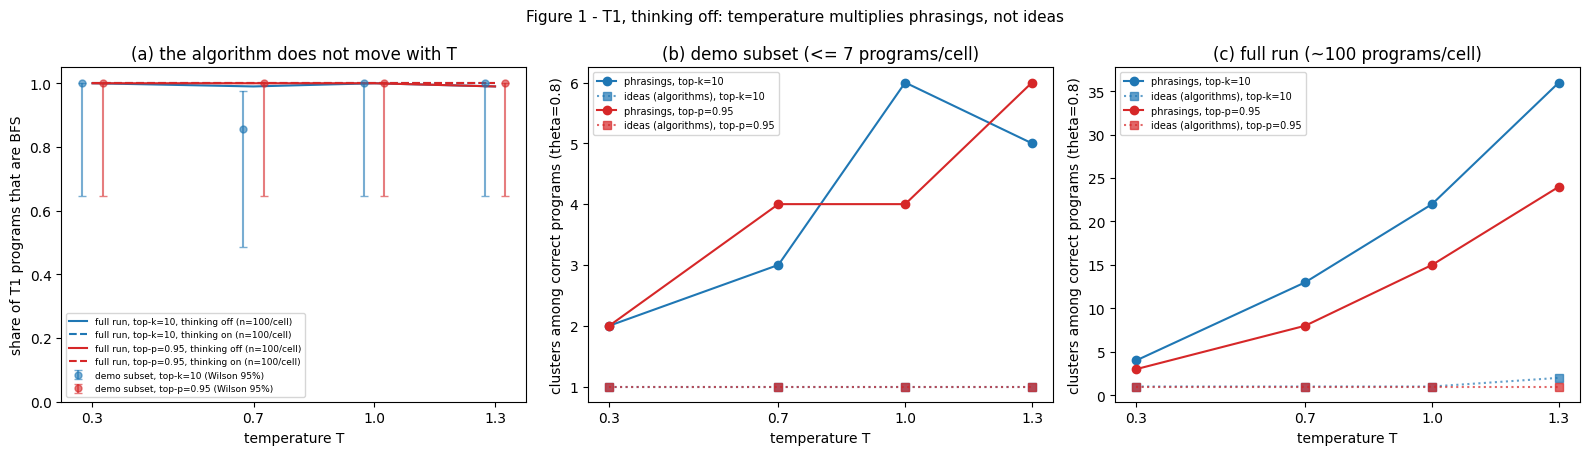

In [19]:
COL = {"topk10": "#1f77b4", "topp095": "#d62728"}
LAB = {"topk10": "top-k=10", "topp095": "top-p=0.95"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# (a) BFS share vs T: full run (lines; solid = thinking off, dashed = thinking on) and the demo subset (points)
ax = axes[0]
for sp in ("topk10", "topp095"):
    for think, ls in ((False, "-"), (True, "--")):
        rs = sorted([r for r in A["bfs_dijkstra_table"] if r["task"] == "T1" and r["sampler"] == sp
                     and r["thinking"] == think], key=lambda r: r["T"])
        ax.plot([r["T"] for r in rs], [r["share_all"]["share"] for r in rs], ls, color=COL[sp], lw=1.5,
                label=f"full run, {LAB[sp]}, thinking {'on' if think else 'off'} (n=100/cell)")
    rs = sorted([r for r in bfs_dijkstra if r["sampler"] == sp], key=lambda r: r["T"])
    if rs:
        x = np.array([r["T"] for r in rs]) + (0.025 if sp == "topp095" else -0.025)
        y = np.array([r["share_all"]["share"] for r in rs])
        lo = np.array([r["share_all"]["wilson95"][0] for r in rs])
        hi = np.array([r["share_all"]["wilson95"][1] for r in rs])
        ax.errorbar(x, y, yerr=[y - lo, hi - y], fmt="o", color=COL[sp], ms=5, capsize=3, alpha=0.6,
                    label=f"demo subset, {LAB[sp]} (Wilson 95%)")
ax.set_ylim(0, 1.05)
ax.set_xticks(TEMPS)
ax.set_xlabel("temperature T")
ax.set_ylabel("share of T1 programs that are BFS")
ax.set_title("(a) the algorithm does not move with T")
ax.legend(fontsize=6.5, loc="lower left")

# (b) demo subset and (c) full run: ideas vs phrasings per T (A1, thinking off)
for ax, src, title, key in ((axes[1], ideas_by_phrasings["table"], f"(b) demo subset (<= {MAX_PER_CELL} programs/cell)",
                             TH_KEY),
                            (axes[2], [r for r in A["ideas_by_phrasings"]["table"] if r["task"] == "T1"],
                             "(c) full run (~100 programs/cell)", f"theta{TH}_single")):
    for sp in ("topk10", "topp095"):
        rs = sorted([r for r in src if r["arm"] == "A1" and r["sampler"] == sp], key=lambda r: r["T"])
        if not rs:
            continue
        ax.plot([r["T"] for r in rs], [r[key]["n_phrasings"] for r in rs], "o-", color=COL[sp],
                label=f"phrasings, {LAB[sp]}")
        ax.plot([r["T"] for r in rs], [r[key]["n_ideas"] for r in rs], "s:", color=COL[sp], alpha=0.7,
                label=f"ideas (algorithms), {LAB[sp]}")
    ax.set_xticks(TEMPS)
    ax.set_xlabel("temperature T")
    ax.set_ylabel(f"clusters among correct programs (theta={TH})")
    ax.set_title(title)
    ax.legend(fontsize=7)
fig.suptitle("Figure 1 - T1, thinking off: temperature multiplies phrasings, not ideas", fontsize=11)
fig.tight_layout()
plt.show()

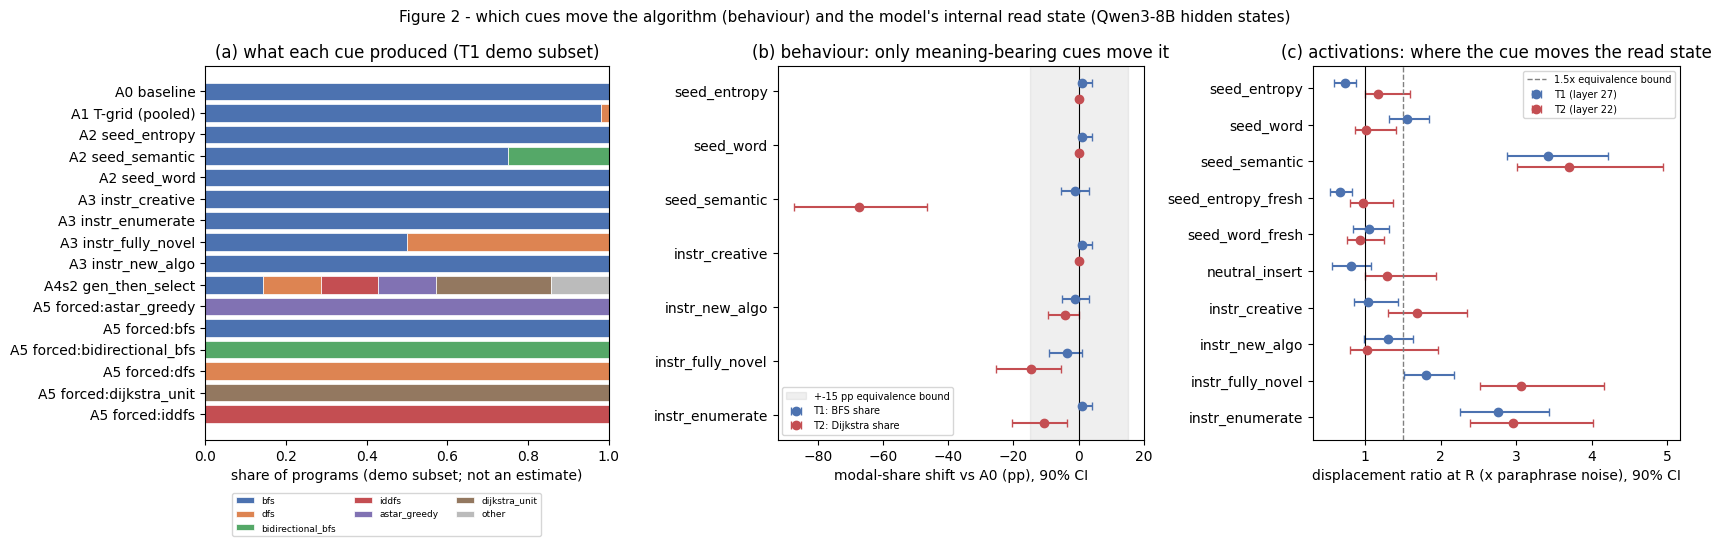

In [20]:
LABEL_COL = {"bfs": "#4c72b0", "dfs": "#dd8452", "bidirectional_bfs": "#55a868", "iddfs": "#c44e52",
             "astar_greedy": "#8172b3", "dijkstra_unit": "#937860", "other": "#bbbbbb", "unparseable": "#eeeeee",
             "unresolved": "#999999"}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.6), gridspec_kw=dict(width_ratios=[1.1, 1, 1]))

# (a) demo subset: algorithm mix per cue (all programs; A1's eight T x sampler cells pooled)
ax = axes[0]
groups = defaultdict(Counter)
for s in SAMPLES:
    g = "A1 T-grid (pooled)" if s["arm"] == "A1" else f"{s['arm']} {s['condition']}"
    groups[g][s["label"]] += 1
order = sorted(groups, key=lambda g: (["A0", "A1", "A2", "A3", "A4s2", "A5"].index(g.split()[0]), g))
left = np.zeros(len(order))
for lab in LABEL_COL:
    v = np.array([groups[g][lab] / sum(groups[g].values()) for g in order])
    if v.sum() > 0:
        ax.barh(order, v, left=left, color=LABEL_COL[lab], label=lab, edgecolor="white", lw=0.5)
        left += v
ax.invert_yaxis()
ax.set_xlabel("share of programs (demo subset; not an estimate)")
ax.set_title("(a) what each cue produced (T1 demo subset)")
ax.legend(fontsize=6.5, loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=3)

# (b) full run: shift of the modal share vs A0 (correct programs), 90% cluster-bootstrap CI
ax = axes[1]
conds = ["seed_entropy", "seed_word", "seed_semantic", "instr_creative", "instr_new_algo", "instr_fully_novel",
         "instr_enumerate"]
for j, (t, colr) in enumerate((("T1", "#4c72b0"), ("T2", "#c44e52"))):
    rs = {r["condition"]: r for r in A["seeds_instructions"] if r["task"] == t}
    y = np.arange(len(conds)) + (j - 0.5) * 0.3
    x = np.array([rs[c]["modal_share_shift_pp"] for c in conds])
    lo = np.array([rs[c]["shift_ci90"][0] for c in conds])
    hi = np.array([rs[c]["shift_ci90"][1] for c in conds])
    ax.errorbar(x, y, xerr=[x - lo, hi - x], fmt="o", color=colr, capsize=3,
                label=f"{t}: {'BFS' if t == 'T1' else 'Dijkstra'} share")
ax.axvspan(-15, 15, color="grey", alpha=0.12, label="+-15 pp equivalence bound")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(np.arange(len(conds)))
ax.set_yticklabels(conds)
ax.invert_yaxis()
ax.set_xlabel("modal-share shift vs A0 (pp), 90% CI")
ax.set_title("(b) behaviour: only meaning-bearing cues move it")
ax.legend(fontsize=7, loc="lower left")

# (c) full run: read-position displacement in the mode subspace / baseline-paraphrase noise, layer l*
ax = axes[2]
rconds = list(A["subspace_test"]["T1"]["l_star"]["conditions"])
for j, (t, colr) in enumerate((("T1", "#4c72b0"), ("T2", "#c44e52"))):
    cc = A["subspace_test"][t]["l_star"]["conditions"]
    y = np.arange(len(rconds)) + (j - 0.5) * 0.3
    x = np.array([cc[c]["ratio"] for c in rconds])
    lo = np.array([cc[c]["ratio_ci90"][0] for c in rconds])
    hi = np.array([cc[c]["ratio_ci90"][1] for c in rconds])
    ax.errorbar(x, y, xerr=[x - lo, hi - x], fmt="o", color=colr, capsize=3,
                label=f"{t} (layer {A['subspace_test'][t]['l_star']['layer']})")
ax.axvline(1.0, color="k", lw=0.8)
ax.axvline(1.5, color="grey", ls="--", lw=1, label="1.5x equivalence bound")
ax.set_yticks(np.arange(len(rconds)))
ax.set_yticklabels(rconds)
ax.invert_yaxis()
ax.set_xlabel("displacement ratio at R (x paraphrase noise), 90% CI")
ax.set_title("(c) activations: where the cue moves the read state")
ax.legend(fontsize=7, loc="upper right")
fig.suptitle("Figure 2 - which cues move the algorithm (behaviour) and the model's internal read state "
             "(Qwen3-8B hidden states)", fontsize=11)
fig.tight_layout()
plt.show()

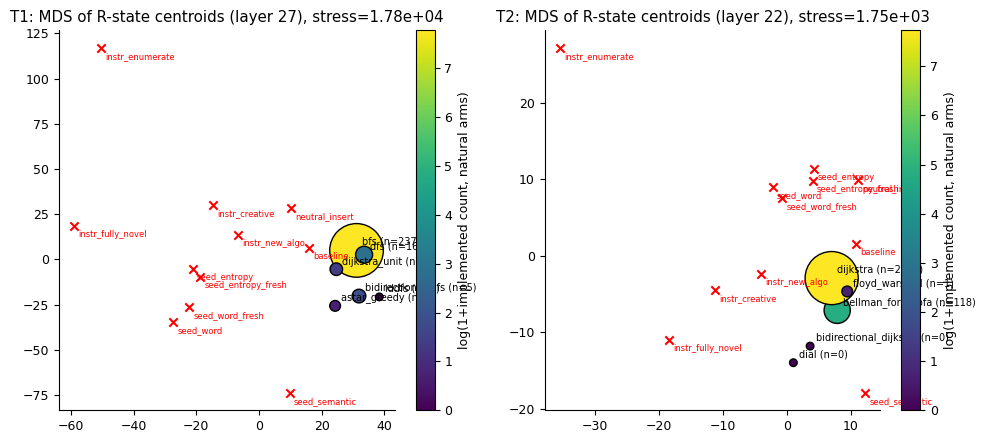

MDS stress here: {'T1': 17828.0, 'T2': 1745.0} | recorded in the artifact: {'T1': 21769.3, 'T2': 1997.1} (SMACOF is a local optimiser, so the layout and stress depend on the scikit-learn version: the artifact ran 1.9.1, this notebook pins Colab's 1.6.1)
Prompts per centroid: {'T1': ({'astar_greedy': 20, 'bfs': 20, 'bidirectional_bfs': 20, 'dfs': 20, 'dijkstra_unit': 20, 'iddfs': 20}, 'conditions: 10 each'), 'T2': ({'bellman_ford_spfa': 20, 'bidirectional_dijkstra': 20, 'dial': 20, 'dijkstra': 20, 'floyd_warshall': 20}, 'conditions: 10 each')}


In [21]:
# ---- analysis/figures.py: fig5_mds (verbatim except the inputs: the 0.8 GB of hidden states are not part of the
#      demo, so the centroid distance matrix D and the natural-arm label counts it derives come from `data`) ----
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})


def _save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=180)
    fig.savefig(FIGURES / f"{name}.pdf")
    plt.show()   # original: plt.close(fig)  (the notebook shows the figure as well as saving it)


def fig5_mds(A, samples):
    from sklearn.manifold import MDS
    meta = data["states_meta"]           # json.loads((STATES / "meta.json").read_text())
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    stress = {}
    for ax, task in zip(axes, ("T1", "T2")):
        l = meta["l_star"][task]
        rc = data["r_centroids"][task]
        # Hn = np.load(STATES / f"R_named_{task}.npy", mmap_mode="r")[:, l].astype(np.float64)
        # Hc = np.load(STATES / f"R_conditions_{task}.npy", mmap_mode="r")[:, l].astype(np.float64)
        # yn = np.array([r["condition"].split(":")[1] for r in meta[f"R_named_{task}"]])
        # rows = meta[f"R_conditions_{task}"]
        modes = rc["modes"]              # sorted(set(yn.tolist()))
        conds = rc["conditions"]         # sorted({r["condition"] for r in rows})
        # pts = [Hn[yn == m].mean(0) for m in modes] + [Hc[[i for i, r in enumerate(rows) if r["condition"] == c]].mean(0)
        #                                               for c in conds]
        # P = np.array(pts)
        # D = np.linalg.norm(P[:, None] - P[None], axis=2)
        D = np.array(rc["D"])
        mds = MDS(n_components=2, dissimilarity="precomputed", random_state=0, normalized_stress="auto")
        Y = mds.fit_transform(D)
        stress[task] = float(mds.stress_)
        # nat = Counter(s["label"] for s in samples if s["task"] == task and s["arm"] in ("A0", "A1", "A2", "A3")
        #               or (s["task"] == task and s["arm"].startswith("A6")))
        nat = Counter(rc["natural_label_counts"])   # the same count over the full run (the demo subset is T1 only)
        sizes = [30 + 3 * np.sqrt(nat.get(m, 0)) * 10 for m in modes]
        sc = ax.scatter(Y[:len(modes), 0], Y[:len(modes), 1], s=sizes, c=[np.log1p(nat.get(m, 0)) for m in modes],
                        cmap="viridis", edgecolor="k", zorder=3)
        for k, m in enumerate(modes):
            ax.annotate(f"{m} (n={nat.get(m, 0)})", Y[k], fontsize=7, xytext=(4, 4), textcoords="offset points")
        ax.scatter(Y[len(modes):, 0], Y[len(modes):, 1], marker="x", color="r", zorder=4)
        for k, c in enumerate(conds):
            ax.annotate(c, Y[len(modes) + k], fontsize=6, color="r", xytext=(3, -8), textcoords="offset points")
        ax.set_title(f"{task}: MDS of R-state centroids (layer {l}), stress={stress[task]:.3g}")
        plt.colorbar(sc, ax=ax, label="log(1+implemented count, natural arms)")
    _save(fig, "fig5_mds_centroids")
    return stress


mds_stress = fig5_mds(A, SAMPLES)
print("MDS stress here:", {t: round(v, 1) for t, v in mds_stress.items()},
      "| recorded in the artifact:", {t: round(v, 1) for t, v in A["figures"]["mds_stress"].items()},
      "(SMACOF is a local optimiser, so the layout and stress depend on the scikit-learn version: the artifact "
      "ran 1.9.1, this notebook pins Colab's 1.6.1)")
print("Prompts per centroid:", {t: (data["r_centroids"][t]["n_named_prompts"], "conditions: 10 each")
                                for t in ("T1", "T2")})

## Takeaways

- **Temperature is a phrasing knob, not an idea knob.** Across T ∈ [0.3, 1.3], two samplers and thinking on or off,
  Qwen3-8B writes BFS for grid path search (T1) and Dijkstra for weighted shortest path (T2) in ≥ 99% of programs.
  The number of distinct phrasings climbs steeply with T (Figure 1).
- **Random context seeds do nothing measurable.** `seed=d32qxk4nt43` and `seed=(horse chair roof love)` shift the
  modal share by ≤ 1 pp. In activation space the entropy seed stays within paraphrase noise; the word seed moves the
  T1 read state 1.56× (Figure 2c).
- **Meaning moves the model.** The semantic seed, a story that implies an approach without naming it, moves the
  read state 3.4–3.7× the paraphrase noise and turns 66 pp of T2 programs into Bellman-Ford. In the MDS (Figure 3)
  the entropy seed and the neutral insert stay near the baseline centroid, while the semantic seed and the
  "fully novel" and "list 10" instructions land far from it.
- **Asking for novelty helps a little, at a price.** "Fully novel" and "list 10 then implement" cut T2 Dijkstra by
  15 and 11 pp. Gen-then-select reaches about 4 (T1) and 3 (T2) distinct ideas per 25 programs, against 1.3 and 1.0
  for the baseline, but passes only 55% and 75% of the hidden tests.

**Caveat:** the labeller gate failed by its strict criteria on both tasks, so every number here is descriptive.
References agree 100%, population κ(runtime, AST) is 0.88 / 0.85, and agreement on correct gold programs is 92%.

**Running the full pipeline.** The artifact's code and outputs are published next to this demo, in `../src/`
(repository path `round-1/experiment-6/src/`). That folder holds `method.py`, `common.py`, `labeller/`,
`analysis/`, `results/`, `figures/` and `full_method_out.json`. From inside it, you need one GPU with ≥ 20 GB,
Qwen3-8B, and an OpenRouter key for the judge:

```bash
uv venv .venv --python 3.12 && uv pip install --python .venv/bin/python -r pyproject.toml
huggingface-cli download Qwen/Qwen3-8B --revision b968826d9c46dd6066d109eabc6255188de91218
export OPENROUTER_API_KEY=...  OPENROUTER_BASE_URL=...
.venv/bin/python method.py all      # setup -> generate -> label -> gate -> hooks -> analyze -> output
```

To use the artifact's full scale in this notebook, set the configuration cell to `N_BOOT_SHARE = 2000`,
`N_BOOT_PHRASING = 1000`, `DA_K = 25`, `DA_K_MODAL = 20`, `THETAS = (0.7, 0.8, 0.9)` and
`LINKAGES = ("single", "complete")`, and feed it every row of `results/samples.jsonl` (about 100 programs per cell).